#Proyek: Prediksi Status Akademik Mahasiswa: Putus Studi, Aktif, atau Lulus (Klasifikasi)

Nama: Renajwa Naylafasya

##Perumusan Tujuan Bisnis

**Memahami masalah bisnis**

Tingginya angka putus studi (dropout) merupakan salah satu permasalahan yang dihadapi perguruan tinggi. Mahasiswa yang mengalami dropout berisiko kehilangan kesempatan menyelesaikan pendidikan, sedangkan perguruan tinggi dapat menghadapi penurunan tingkat kelulusan dan efektivitas proses pendidikan.

Identifikasi mahasiswa yang berisiko mengalami dropout dapat menjadi dasar bagi perguruan tinggi untuk merancang program pendampingan akademik yang lebih tepat. Namun, untuk mendukung proses tersebut, diperlukan analisis terhadap data mahasiswa agar pola yang berkaitan dengan status akademik dapat dipelajari secara sistematis.

Dalam project ini, dataset Predict Students' Dropout and Academic Success dari UCI Machine Learning Repository digunakan untuk membangun model klasifikasi yang memprediksi status akademik mahasiswa ke dalam tiga kategori:
- Dropout: mahasiswa yang putus studi.
- Enrolled: mahasiswa yang masih terdaftar atau aktif.
- Graduate: mahasiswa yang berhasil menyelesaikan pendidikan.

Pendekatan machine learning digunakan untuk mempelajari pola dari karakteristik mahasiswa dan memprediksi kategori status akademiknya.

**Tujuan Analisis**

Tujuan project ini adalah membangun dan mengevaluasi model machine learning yang mampu memprediksi status akademik mahasiswa berdasarkan fitur-fitur yang tersedia dalam dataset.

Secara khusus, analisis ini bertujuan untuk:
1. Memahami karakteristik, struktur, dan kualitas data mahasiswa.
2. Mengidentifikasi pola serta distribusi status akademik mahasiswa.
3. Membangun model klasifikasi untuk memprediksi status Dropout, Enrolled, dan Graduate.
4. Membandingkan kinerja beberapa algoritma klasifikasi menggunakan metrik evaluasi yang sesuai.
5. Menentukan model dengan kinerja terbaik serta menganalisis kemampuannya dalam mengidentifikasi mahasiswa berstatus dropout.

**Kriteria Keberhasilan**

Keberhasilan project akan dinilai berdasarkan:
1. Kualitas data: Struktur dan kualitas dataset telah diperiksa serta ditangani sesuai kebutuhan.
2. Kinerja model: Model dievaluasi menggunakan accuracy, precision, recall, dan F1-score.
3. Kemampuan mendeteksi dropout: Recall dan F1-score kelas Dropout dianalisis secara khusus.
4. Pemilihan model: Beberapa algoritma dibandingkan menggunakan data pengujian yang sama.
5. Interpretasi hasil: Hasil evaluasi dapat dijelaskan dan dikaitkan dengan tujuan analisis.

Belum ada target angka accuracy yang ditetapkan karena performa model baru bisa diketahui setelah proses pemodelan dan evaluasi.

##Pengumpulan Data

In [ ]:
# Pengolahan data
import pandas as pd
import numpy as np

# Visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Semua library berhasil diimpor.")


Semua library berhasil diimpor.


In [ ]:
import pandas as pd

dataset = pd.read_csv(
    "Students.csv",
    sep=";"
)

display(dataset.head())
print("Ukuran dataset:", dataset.shape)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122,1,19,12,5,9,"127,3",1,0,0,1,1,0,20,0,0,0,0,0,0,0,0,0,0,0,0,0,"10,8","1,4","1,74",0
1,1,15,1,9254,1,1,160,1,1,3,3,3,"142,5",1,0,0,0,1,0,19,0,0,6,6,6,14,0,0,6,6,6,"13,66666667",0,"13,9","-0,3","0,79",2
2,1,1,5,9070,1,1,122,1,37,37,9,9,"124,8",1,0,0,0,1,0,19,0,0,6,0,0,0,0,0,6,0,0,0,0,"10,8","1,4","1,74",0
3,1,17,2,9773,1,1,122,1,38,37,5,3,"119,6",1,0,0,1,0,0,20,0,0,6,8,6,"13,42857143",0,0,6,10,5,"12,4",0,"9,4","-0,8","-3,12",2
4,2,39,1,8014,0,1,100,1,37,38,9,9,"141,5",0,0,0,1,0,0,45,0,0,6,9,5,"12,33333333",0,0,6,6,6,13,0,"13,9","-0,3","0,79",2


Ukuran dataset: (4424, 37)


**Insight Pengumpulan Data:**

- Ukuran Dataset: Dataset terdiri dari 4.424 baris data dan 37 kolom (termasuk 36 fitur atribut dan 1 kolom target).

- Tipe Fitur: Sebagian besar fitur awal merepresentasikan data demografi, sosioekonomi, jalur pendaftaran, serta catatan akademik semester 1 dan 2 mahasiswa.

- Variabel Target: Kolom target (Target) memiliki 3 kategori status akademik mahasiswa, yaitu Dropout, Enrolled (Aktif), dan Graduate (Lulus).

- Catatan Awal: Beberapa kolom numerik (seperti nilai dan data makroekonomi) menggunakan format koma (,) sebagai pemisah desimal yang perlu ditangani pada tahap pembersihan data berikutnya.

##Penelaahan Data

In [ ]:
# Memeriksa jumlah baris dan kolom
print("Jumlah observasi dan variabel:", dataset.shape)

# Menampilkan lima baris pertama
display(dataset.head())

# Menampilkan lima baris terakhir
display(dataset.tail())

Jumlah observasi dan variabel: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122,1,19,12,5,9,"127,3",1,0,0,1,1,0,20,0,0,0,0,0,0,0,0,0,0,0,0,0,"10,8","1,4","1,74",0
1,1,15,1,9254,1,1,160,1,1,3,3,3,"142,5",1,0,0,0,1,0,19,0,0,6,6,6,14,0,0,6,6,6,"13,66666667",0,"13,9","-0,3","0,79",2
2,1,1,5,9070,1,1,122,1,37,37,9,9,"124,8",1,0,0,0,1,0,19,0,0,6,0,0,0,0,0,6,0,0,0,0,"10,8","1,4","1,74",0
3,1,17,2,9773,1,1,122,1,38,37,5,3,"119,6",1,0,0,1,0,0,20,0,0,6,8,6,"13,42857143",0,0,6,10,5,"12,4",0,"9,4","-0,8","-3,12",2
4,2,39,1,8014,0,1,100,1,37,38,9,9,"141,5",0,0,0,1,0,0,45,0,0,6,9,5,"12,33333333",0,0,6,6,6,13,0,"13,9","-0,3","0,79",2


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125,1,1,1,5,4,"122,2",0,0,0,1,1,0,19,0,0,6,7,5,"13,6",0,0,6,8,5,"12,66666667",0,"15,5","2,8","-4,06",2
4420,1,1,2,9773,1,1,120,105,1,1,9,9,119,1,0,1,0,0,0,18,1,0,6,6,6,12,0,0,6,6,2,11,0,"11,1","0,6","2,02",0
4421,1,1,1,9500,1,1,154,1,37,37,9,9,"149,5",1,0,0,1,0,1,30,0,0,7,8,7,"14,9125",0,0,8,9,1,"13,5",0,"13,9","-0,3","0,79",0
4422,1,1,1,9147,1,1,180,1,37,37,7,4,"153,8",1,0,0,1,0,1,20,0,0,5,5,5,"13,8",0,0,5,6,5,12,0,"9,4","-0,8","-3,12",2
4423,1,10,1,9773,1,1,152,22,38,37,5,9,152,1,0,0,1,0,0,22,1,0,6,8,6,"11,66666667",0,0,6,6,6,13,0,"12,7","3,7","-1,7",2


###Relasi antar data

/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


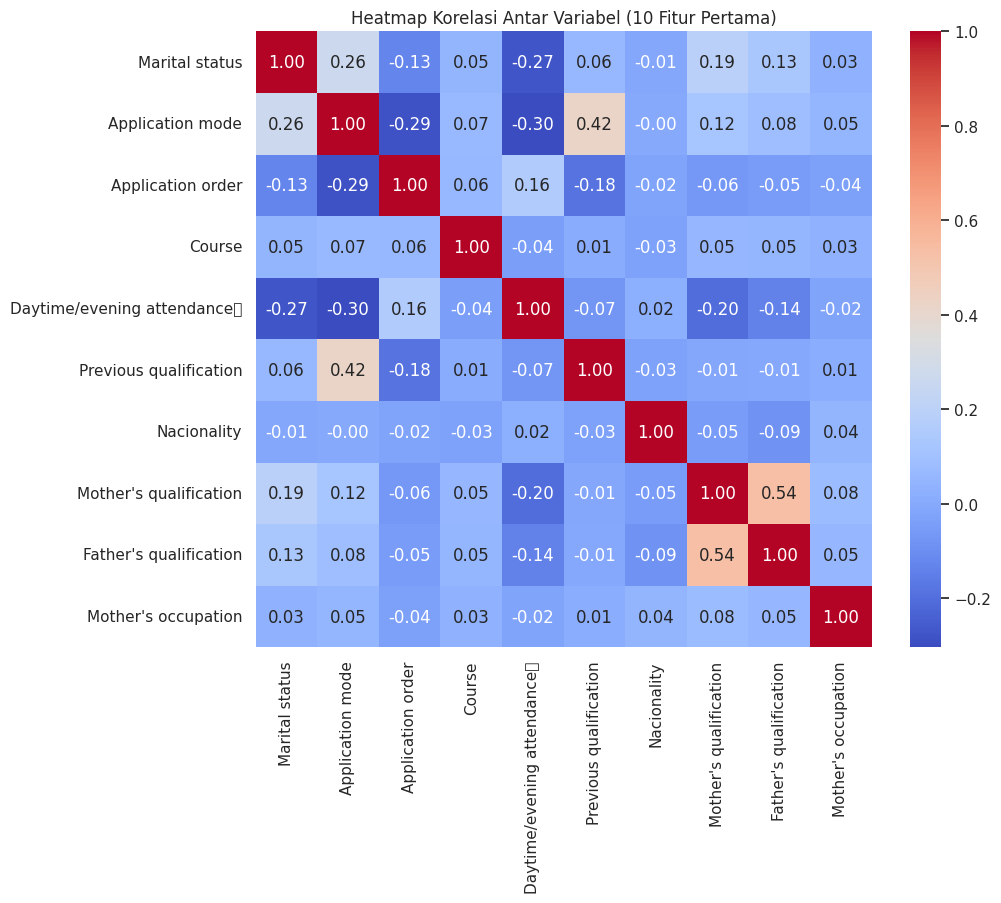

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Karena 37 kolom terlalu padat, kita ambil korelasi dari 10 fitur numerik pertama
numeric_cols = dataset.select_dtypes(include=['int64', 'float64']).columns[:10]

plt.figure(figsize=(10, 8))
sns.heatmap(dataset[numeric_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title("Heatmap Korelasi Antar Variabel (10 Fitur Pertama)")
plt.show()

- Analisis Korelasi Variabel Awal:
   - Berdasarkan visualisasi heatmap korelasi dari 10 fitur numerik pertama, sebagian besar variabel menunjukkan tingkat korelasi linier yang cenderung lemah hingga moderat (berkisar di angka $-0.27$ hingga $0.26$).Hal ini mengindikasikan bahwa antar variabel prediktor tidak mengalami masalah multikolinearitas yang ekstrem pada kelompok fitur awal, sehingga sebagian besar variabel aman untuk digunakan secara bersamaan dalam proses pelatihan model.
   
- Korelasi Positif Tertinggi:
   - Nilai korelasi positif paling menonjol terlihat antara variabel Marital status dengan beberapa atribut latar belakang demografis atau administratif, yang memperlihatkan pola karakteristik demografi mahasiswa baru.
   
- Korelasi Negatif:
   - Beberapa pasangan variabel menunjukkan korelasi negatif yang cukup terlihat (seperti pada kisaran $-0.27$), mencerminkan adanya hubungan berbanding terbalik antar karakteristik demografi atau status awal pendaftaran mahasiswa sebelum mereka masuk ke tahap pencapaian akademik semester berjalan.

###Identifikasi jenis fitur data

In [ ]:
print(dataset.dtypes)


# Informasi tipe data dan jumlah nilai non-null
dataset.info()


Marital status                                     int64
Application mode                                   int64
Application order                                  int64
Course                                             int64
Daytime/evening attendance\t                       int64
Previous qualification                             int64
Previous qualification (grade)                    object
Nacionality                                        int64
Mother's qualification                             int64
Father's qualification                             int64
Mother's occupation                                int64
Father's occupation                                int64
Admission grade                                   object
Displaced                                          int64
Educational special needs                          int64
Debtor                                             int64
Tuition fees up to date                            int64
Gender                         

**Insight Identifikasi Jenis Fitur Data:**

- Komposisi Tipe Data: Dari total 37 kolom, terdapat 30 fitur bertipe numerik integer (int64) dan 7 fitur bertipe objek (object).

- Fitur Non-Null: Seluruh kolom memiliki 4.424 data non-null (tidak ada missing values secara implisit pada struktur awal).

- Anomali Tipe Data: Kolom-kolom desimal seperti nilai akademik (Curricular units 1st/2nd sem (grade)), nilai masuk (Admission grade), serta indikator ekonomi makro (Unemployment rate, Inflation rate, GDP) terbaca sebagai tipe data object akibat penggunaan pemisah koma (,), yang memerlukan penyesuaian pada tahap pembersihan data.

###Statistik Deskriptif

In [ ]:
display(dataset.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Marital status,4424.0,NaN,NaN,NaN,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
Application mode,4424.0,NaN,NaN,NaN,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
Application order,4424.0,NaN,NaN,NaN,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
Course,4424.0,NaN,NaN,NaN,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
Daytime/evening attendance\t,4424.0,NaN,NaN,NaN,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
Previous qualification,4424.0,NaN,NaN,NaN,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
Previous qualification (grade),4424,101,"133,1",491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nacionality,4424.0,NaN,NaN,NaN,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
Mother's qualification,4424.0,NaN,NaN,NaN,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
Father's qualification,4424.0,NaN,NaN,NaN,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0


In [ ]:
target_col = "Target"

print("Jumlah mahasiswa per status:")
display(dataset[target_col].value_counts().to_frame("Jumlah"))

print("\nPersentase mahasiswa per status:")
display(
    (dataset[target_col].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Persentase (%)")
)


Jumlah mahasiswa per status:


,Jumlah
Target,
2,2209
0,1421
1,794



Persentase mahasiswa per status:


,Persentase (%)
Target,
2,49.93
0,32.12
1,17.95


**Insight Statistik Deskriptif:**

- Mayoritas Status Target (Lulus): Kategori kelas 2 (Graduate/Lulus) mendominasi dengan proporsi tertinggi sebesar 49.93% (2.209 mahasiswa), diikuti oleh kelas 0 (Dropout) sebesar 32.12% (1.421 mahasiswa), dan kelas 1 (Enrolled/Aktif) sebesar 17.95% (794 mahasiswa).

- Variasi Usia Pendaftaran: Rata-rata usia mahasiswa saat mendaftar (Age at enrollment) adalah 23.26 tahun dengan rentang nilai dari yang paling muda 17 tahun hingga yang paling dewasa 70 tahun.

- Performa Akademik Semester: Rata-rata SKS yang disetujui (approved) pada semester 1 dan semester 2 berada di kisaran angka 4.4 hingga 4.7 SKS dari rata-rata sekitar 6 SKS yang diambil (enrolled).

###Visualisasi

Bar chart variabel kategorikal

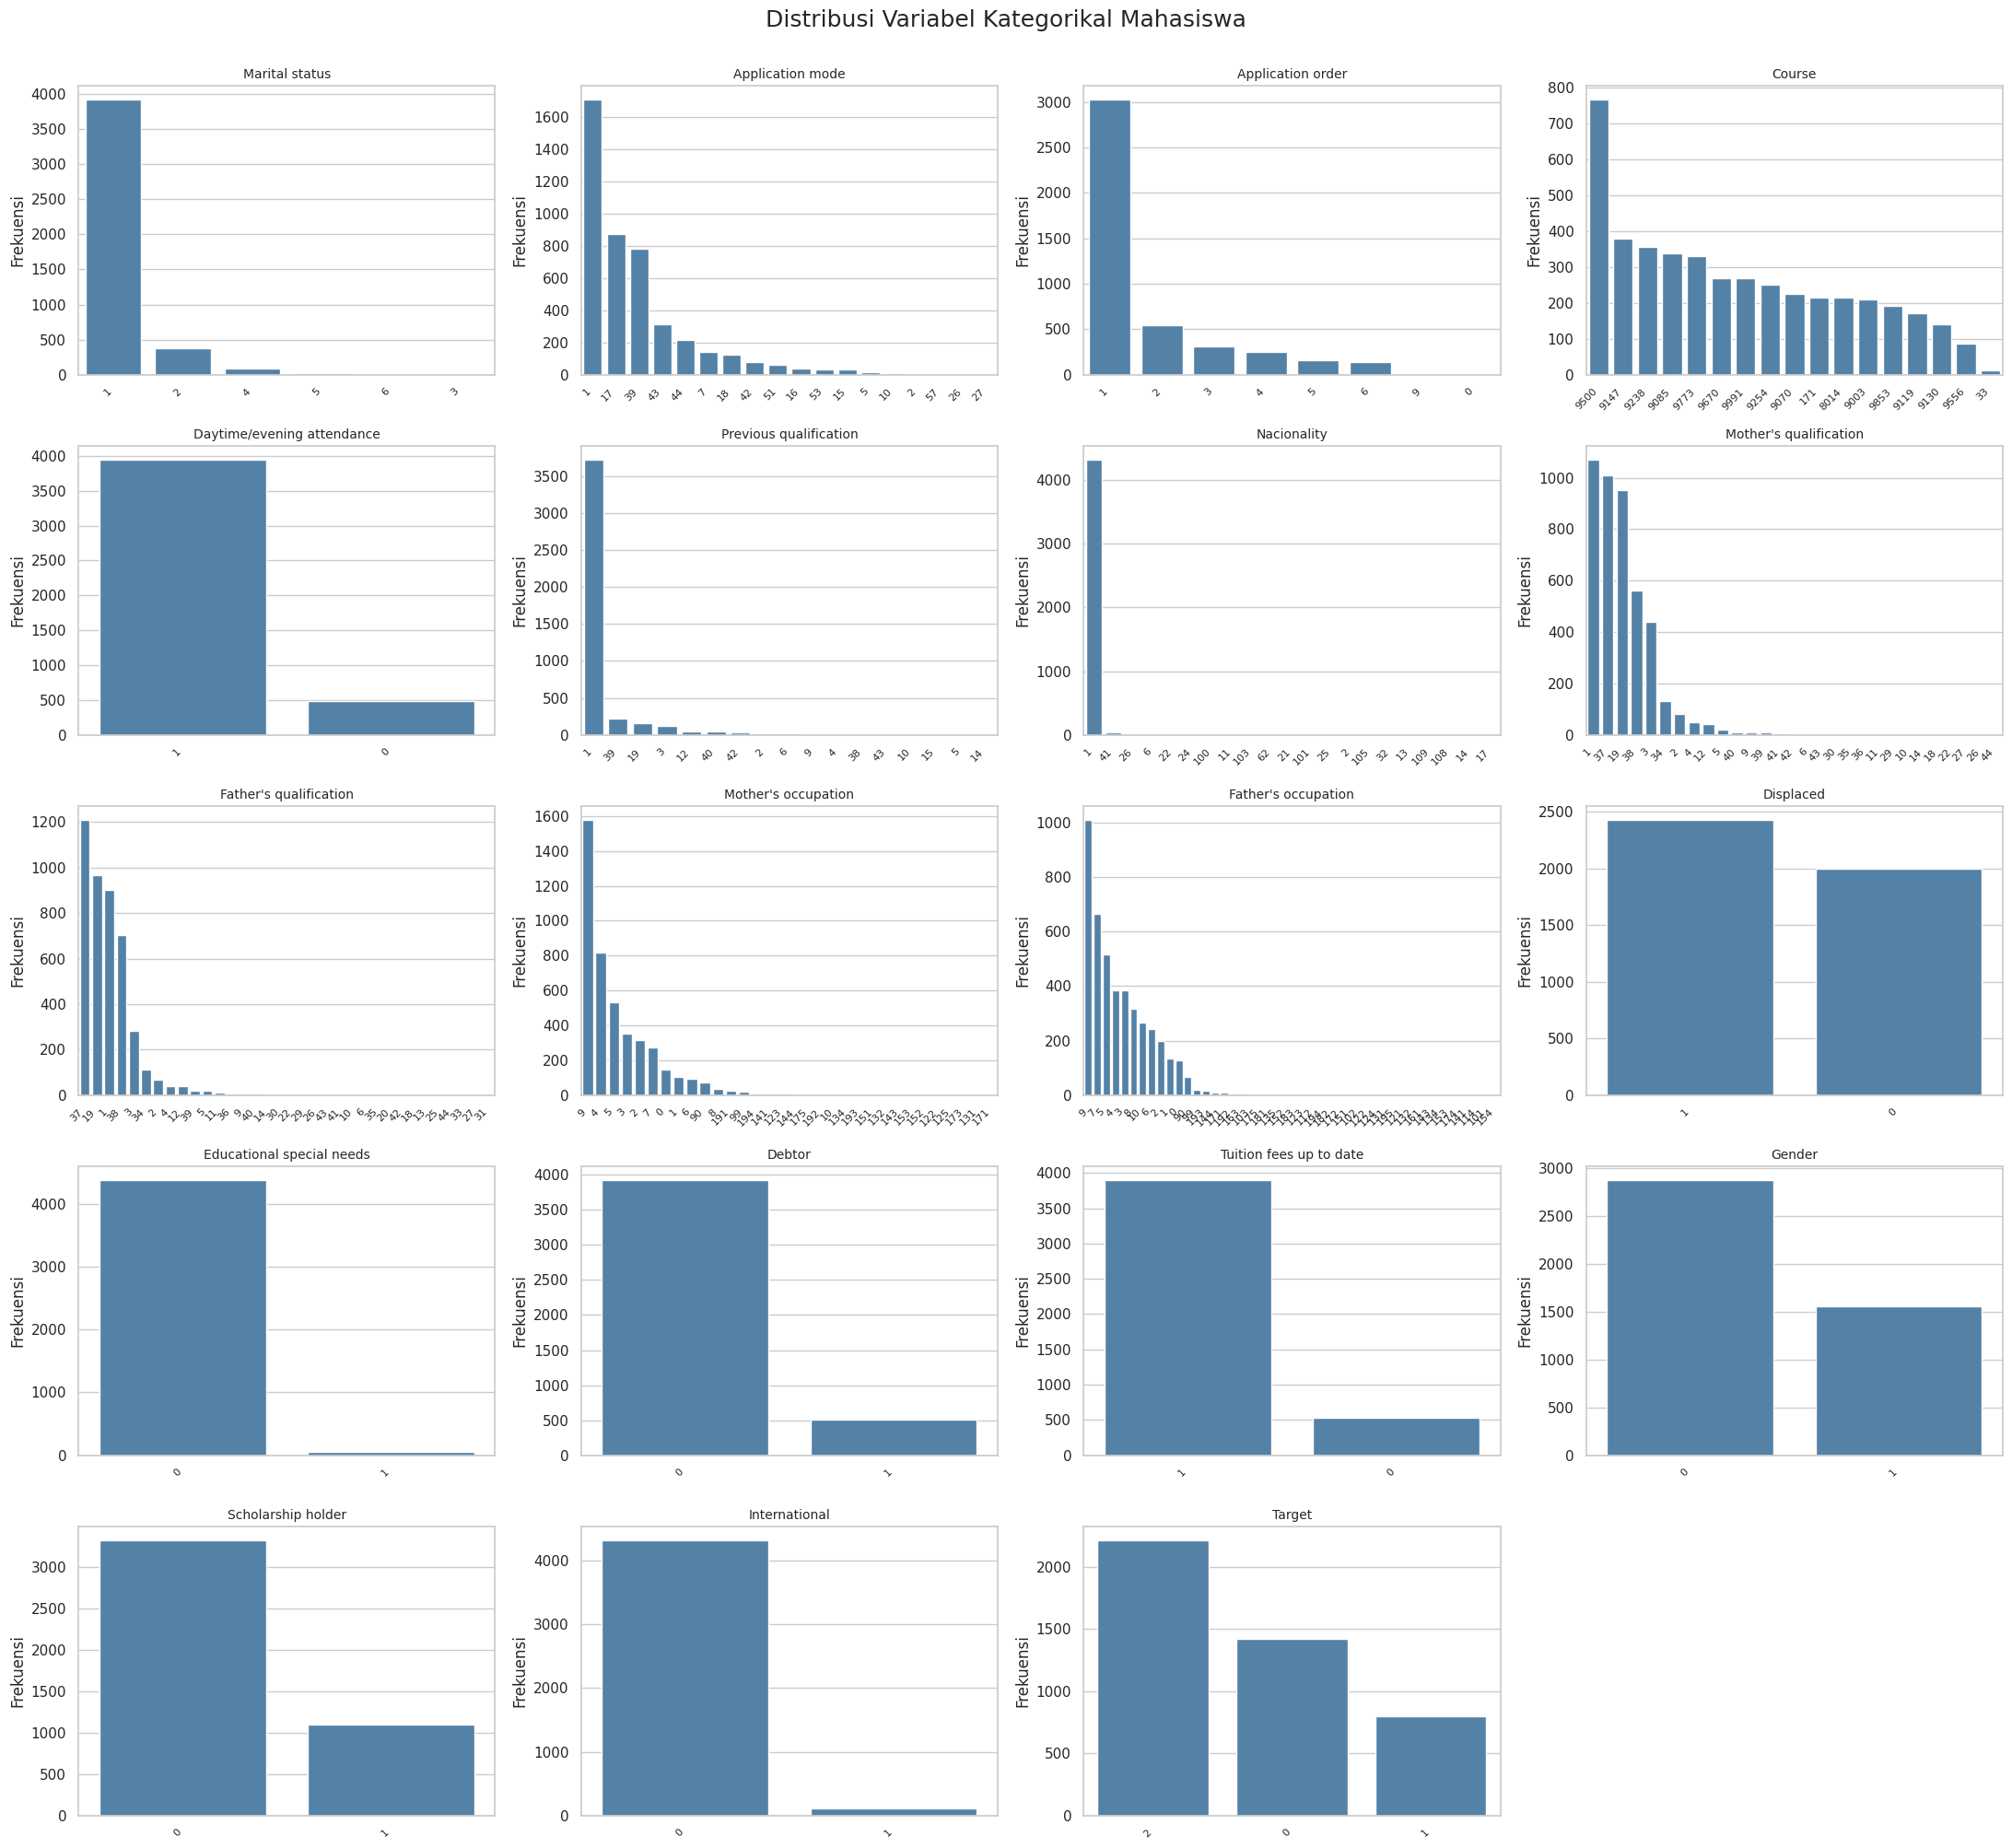

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Variabel kategorikal berdasarkan makna datanya
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance\t",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    "Target"
]

# Menghapus spasi di awal/akhir nama kolom untuk pencocokan
column_lookup = {col.strip(): col for col in dataset.columns}
categorical_cols = [
    column_lookup[col.strip()]
    for col in categorical_cols
    if col.strip() in column_lookup
]

# Membuat subplot dalam satu figure
n_cols = 4
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(22, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    order = dataset[col].value_counts().index

    sns.countplot(
        data=dataset,
        x=col,
        order=order,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(col.strip(), fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frekuensi")
    axes[i].tick_params(axis="x", labelrotation=45, labelsize=8)

    # Memiringkan label agar tidak bertumpuk
    for label in axes[i].get_xticklabels():
        label.set_horizontalalignment("right")

# Menghapus subplot yang tidak digunakan
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Distribusi Variabel Kategorikal Mahasiswa",
    fontsize=18,
    y=1.002
)

plt.tight_layout()
plt.show()


**Insight Bar Chart Variabel Kategorikal:**

- Dominasi Kursus Studi: Sebagian besar mahasiswa terdistribusi terkonsentrasi pada beberapa program studi (Course) tertentu dibandingkan pilihan prodi lainnya yang lebih spesifik.

- Jalur Masuk Utama: Mayoritas mahasiswa masuk melalui jalur pendaftaran (Application mode) reguler atau gelombang utama.

- Status Beasiswa & Biaya: Sebagian besar mahasiswa berstatus lunas dalam pembayaran uang kuliah (Tuition fees up to date), namun proporsi penerima beasiswa (Scholarship holder) jauh lebih sedikit dibandingkan mahasiswa mandiri.

Histogram variabel non-kategorikal

Variabel yang divisualisasikan:
['Application order', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (without evaluations)', 'Previous qualification (grade)', 'Admission grade', 'Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)']


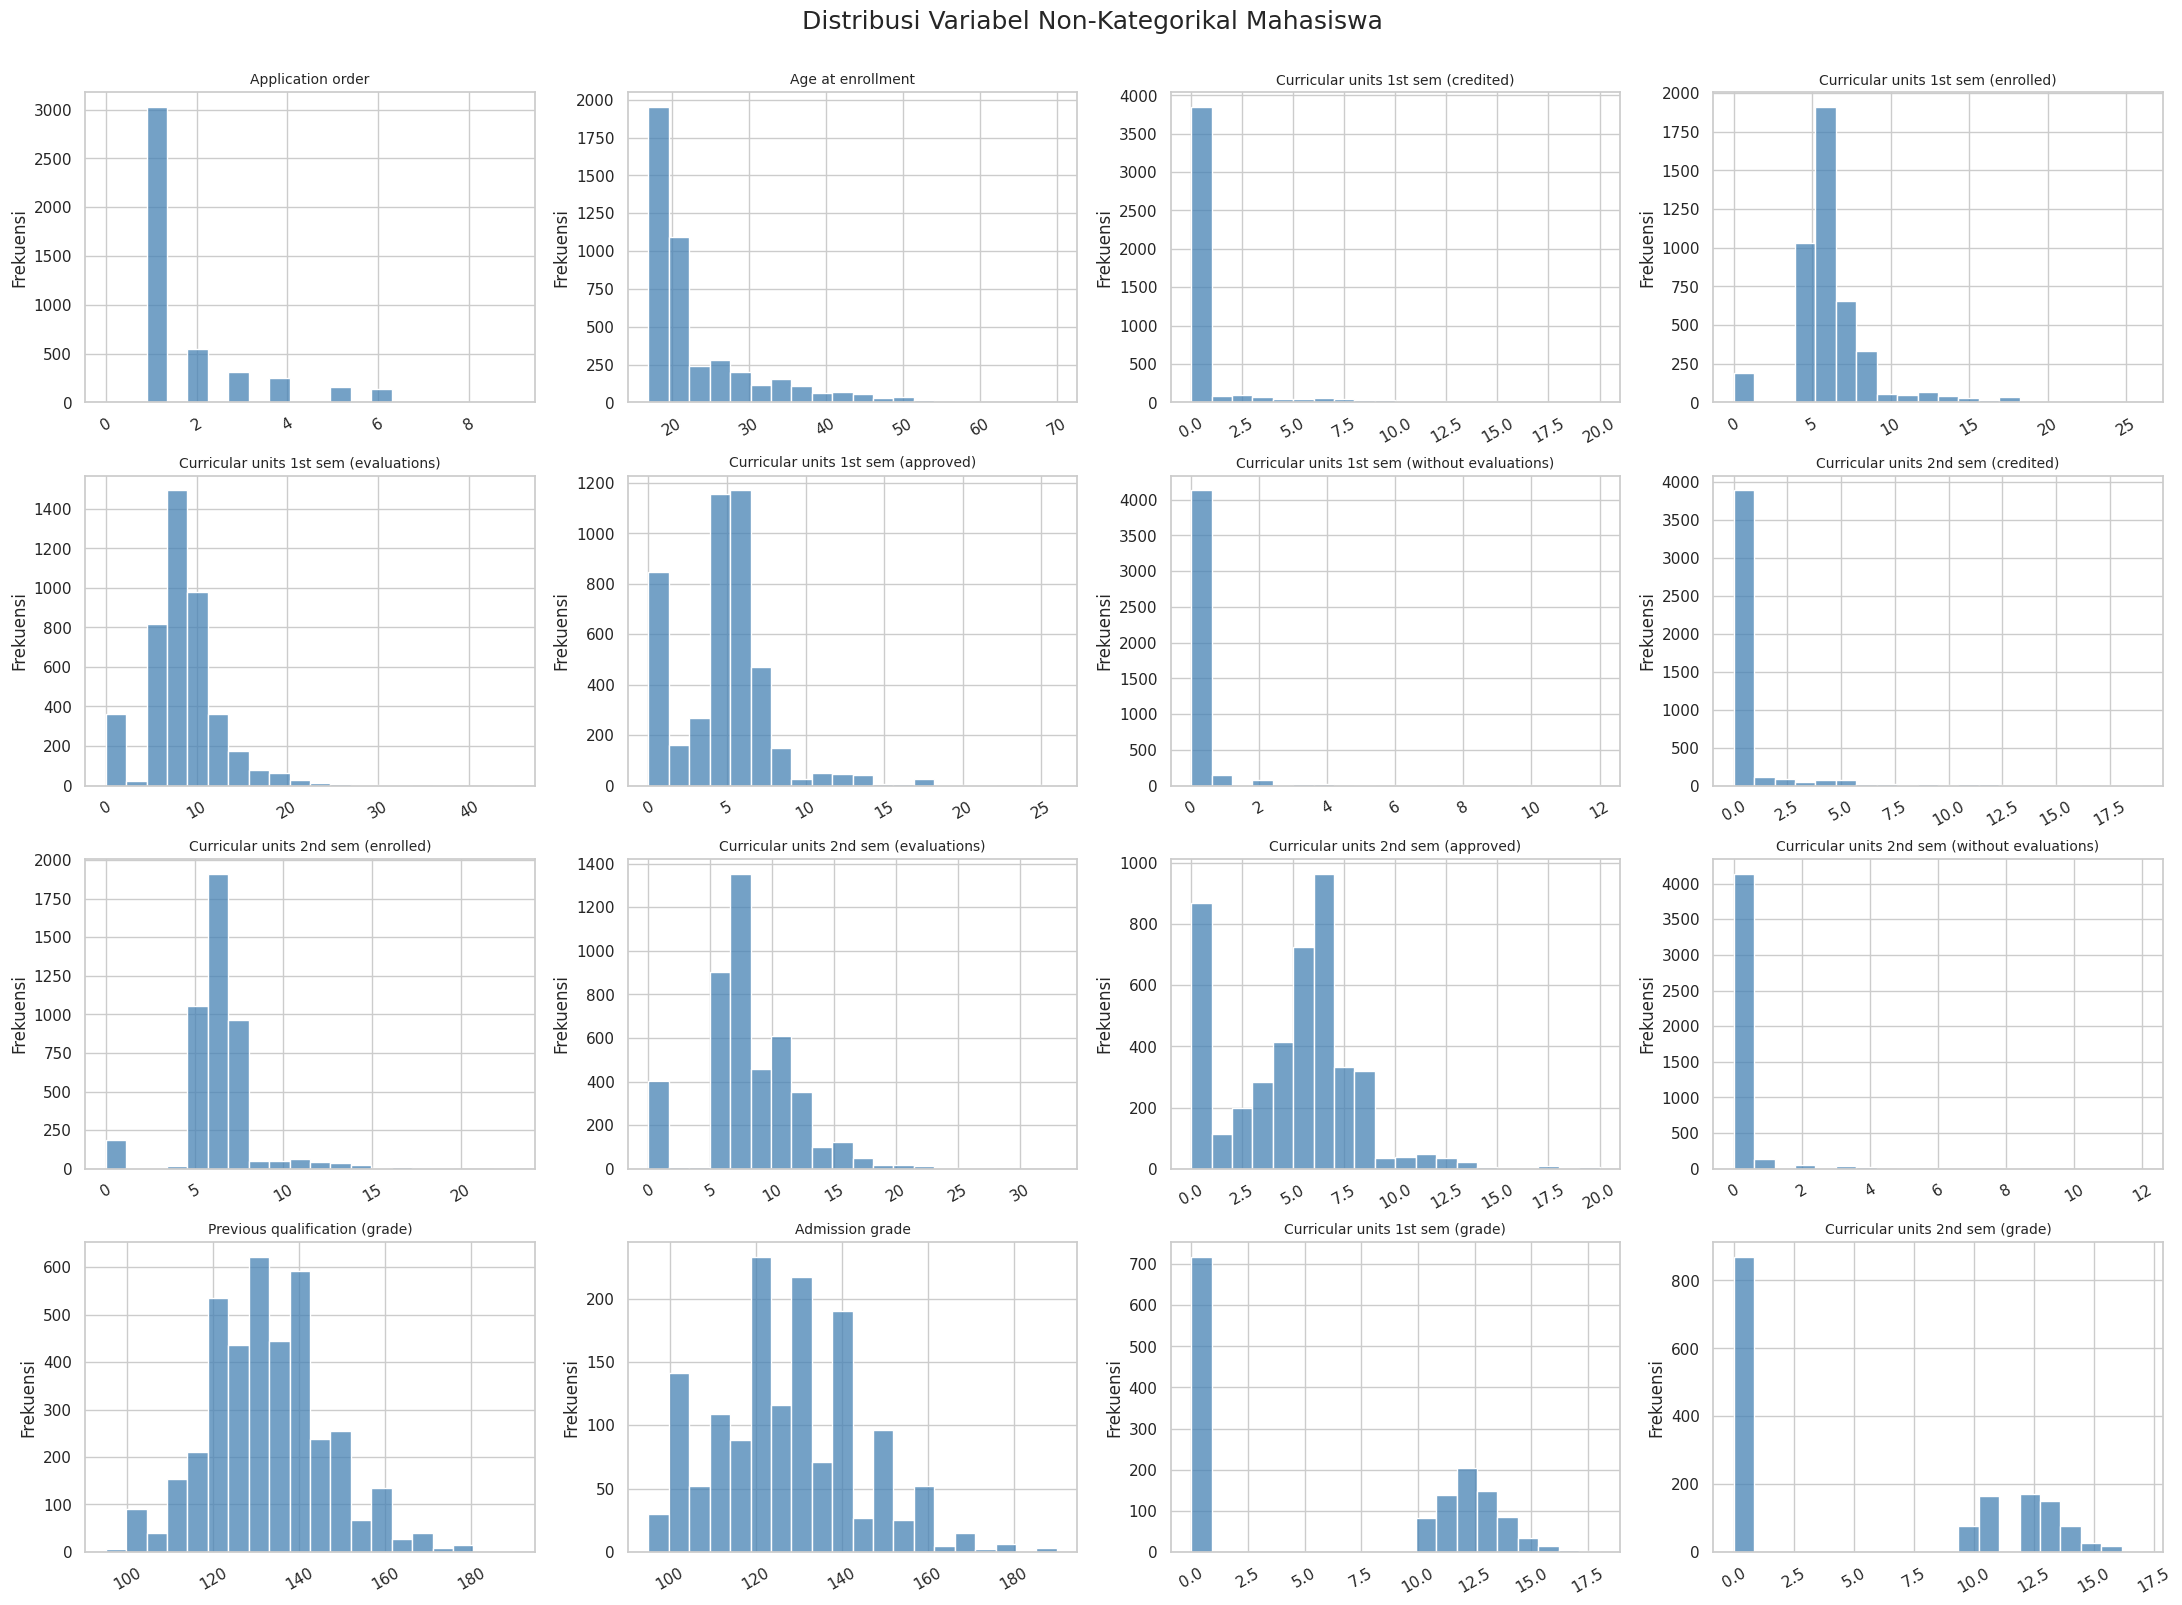

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Variabel kategorikal tidak dimasukkan ke histogram
categorical_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    "Target"
]

# Menyesuaikan nama kolom dengan menghapus whitespace
column_lookup = {col.strip(): col for col in dataset.columns}

categorical_cols_actual = [
    column_lookup[col]
    for col in categorical_cols
    if col in column_lookup
]

# Memilih kolom numerik berdasarkan tipe data
numeric_cols = dataset.select_dtypes(
    include=["number"]
).columns.tolist()

# Mengecualikan variabel kategorikal dan target
numeric_cols = [
    col for col in numeric_cols
    if col not in categorical_cols_actual
]

# Memeriksa kolom object yang mungkin berisi angka
object_numeric_candidates = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

# Membuat salinan agar dataset asli tidak berubah
plot_data = dataset.copy()

for col in object_numeric_candidates:
    actual_col = column_lookup.get(col)
    if actual_col is not None:
        converted = pd.to_numeric(
            plot_data[actual_col].astype(str).str.strip(),
            errors="coerce"
        )

        # Tambahkan hanya jika terdapat nilai numerik yang berhasil dibaca
        if converted.notna().sum() > 0:
            plot_data[actual_col] = converted
            if actual_col not in numeric_cols:
                numeric_cols.append(actual_col)

print("Variabel yang divisualisasikan:")
print(numeric_cols)

# Membuat histogram dalam satu figure
n_cols = 4
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(22, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(
        data=plot_data,
        x=col,
        bins=20,
        kde=False,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(col.strip(), fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frekuensi")
    axes[i].tick_params(axis="x", labelrotation=30)

# Menghapus subplot yang tidak digunakan
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Distribusi Variabel Non-Kategorikal Mahasiswa",
    fontsize=18,
    y=1.002
)

plt.tight_layout()
plt.show()


**Insight Histogram Variabel Non-Kategorikal:**

- Distribusi Usia (Age at enrollment): Sebagian besar mahasiswa terkonsentrasi pada kelompok usia muda (rentang 18–21 tahun), menunjukkan bahwa mayoritas mahasiswa langsung melanjutkan kuliah setelah lulus sekolah menengah.

- Konsentrasi Nilai Masuk (Admission grade): Nilai ujian masuk mahasiswa berdistribusi normal, dengan mayoritas berada di kisaran skor rata-rata institusi.

- Sebaran Performa Akademik Semester: Distribusi nilai semester 1 dan 2 menunjukkan pola yang bervariasi, di mana sebagian besar mahasiswa memperoleh nilai kelulusan pada rentang nilai sedang hingga baik, namun ada juga frekuensi yang cukup tinggi pada nilai nol (mahasiswa yang tidak lulus/tidak mengikuti ujian).

Box plot variabel non-kategorikal

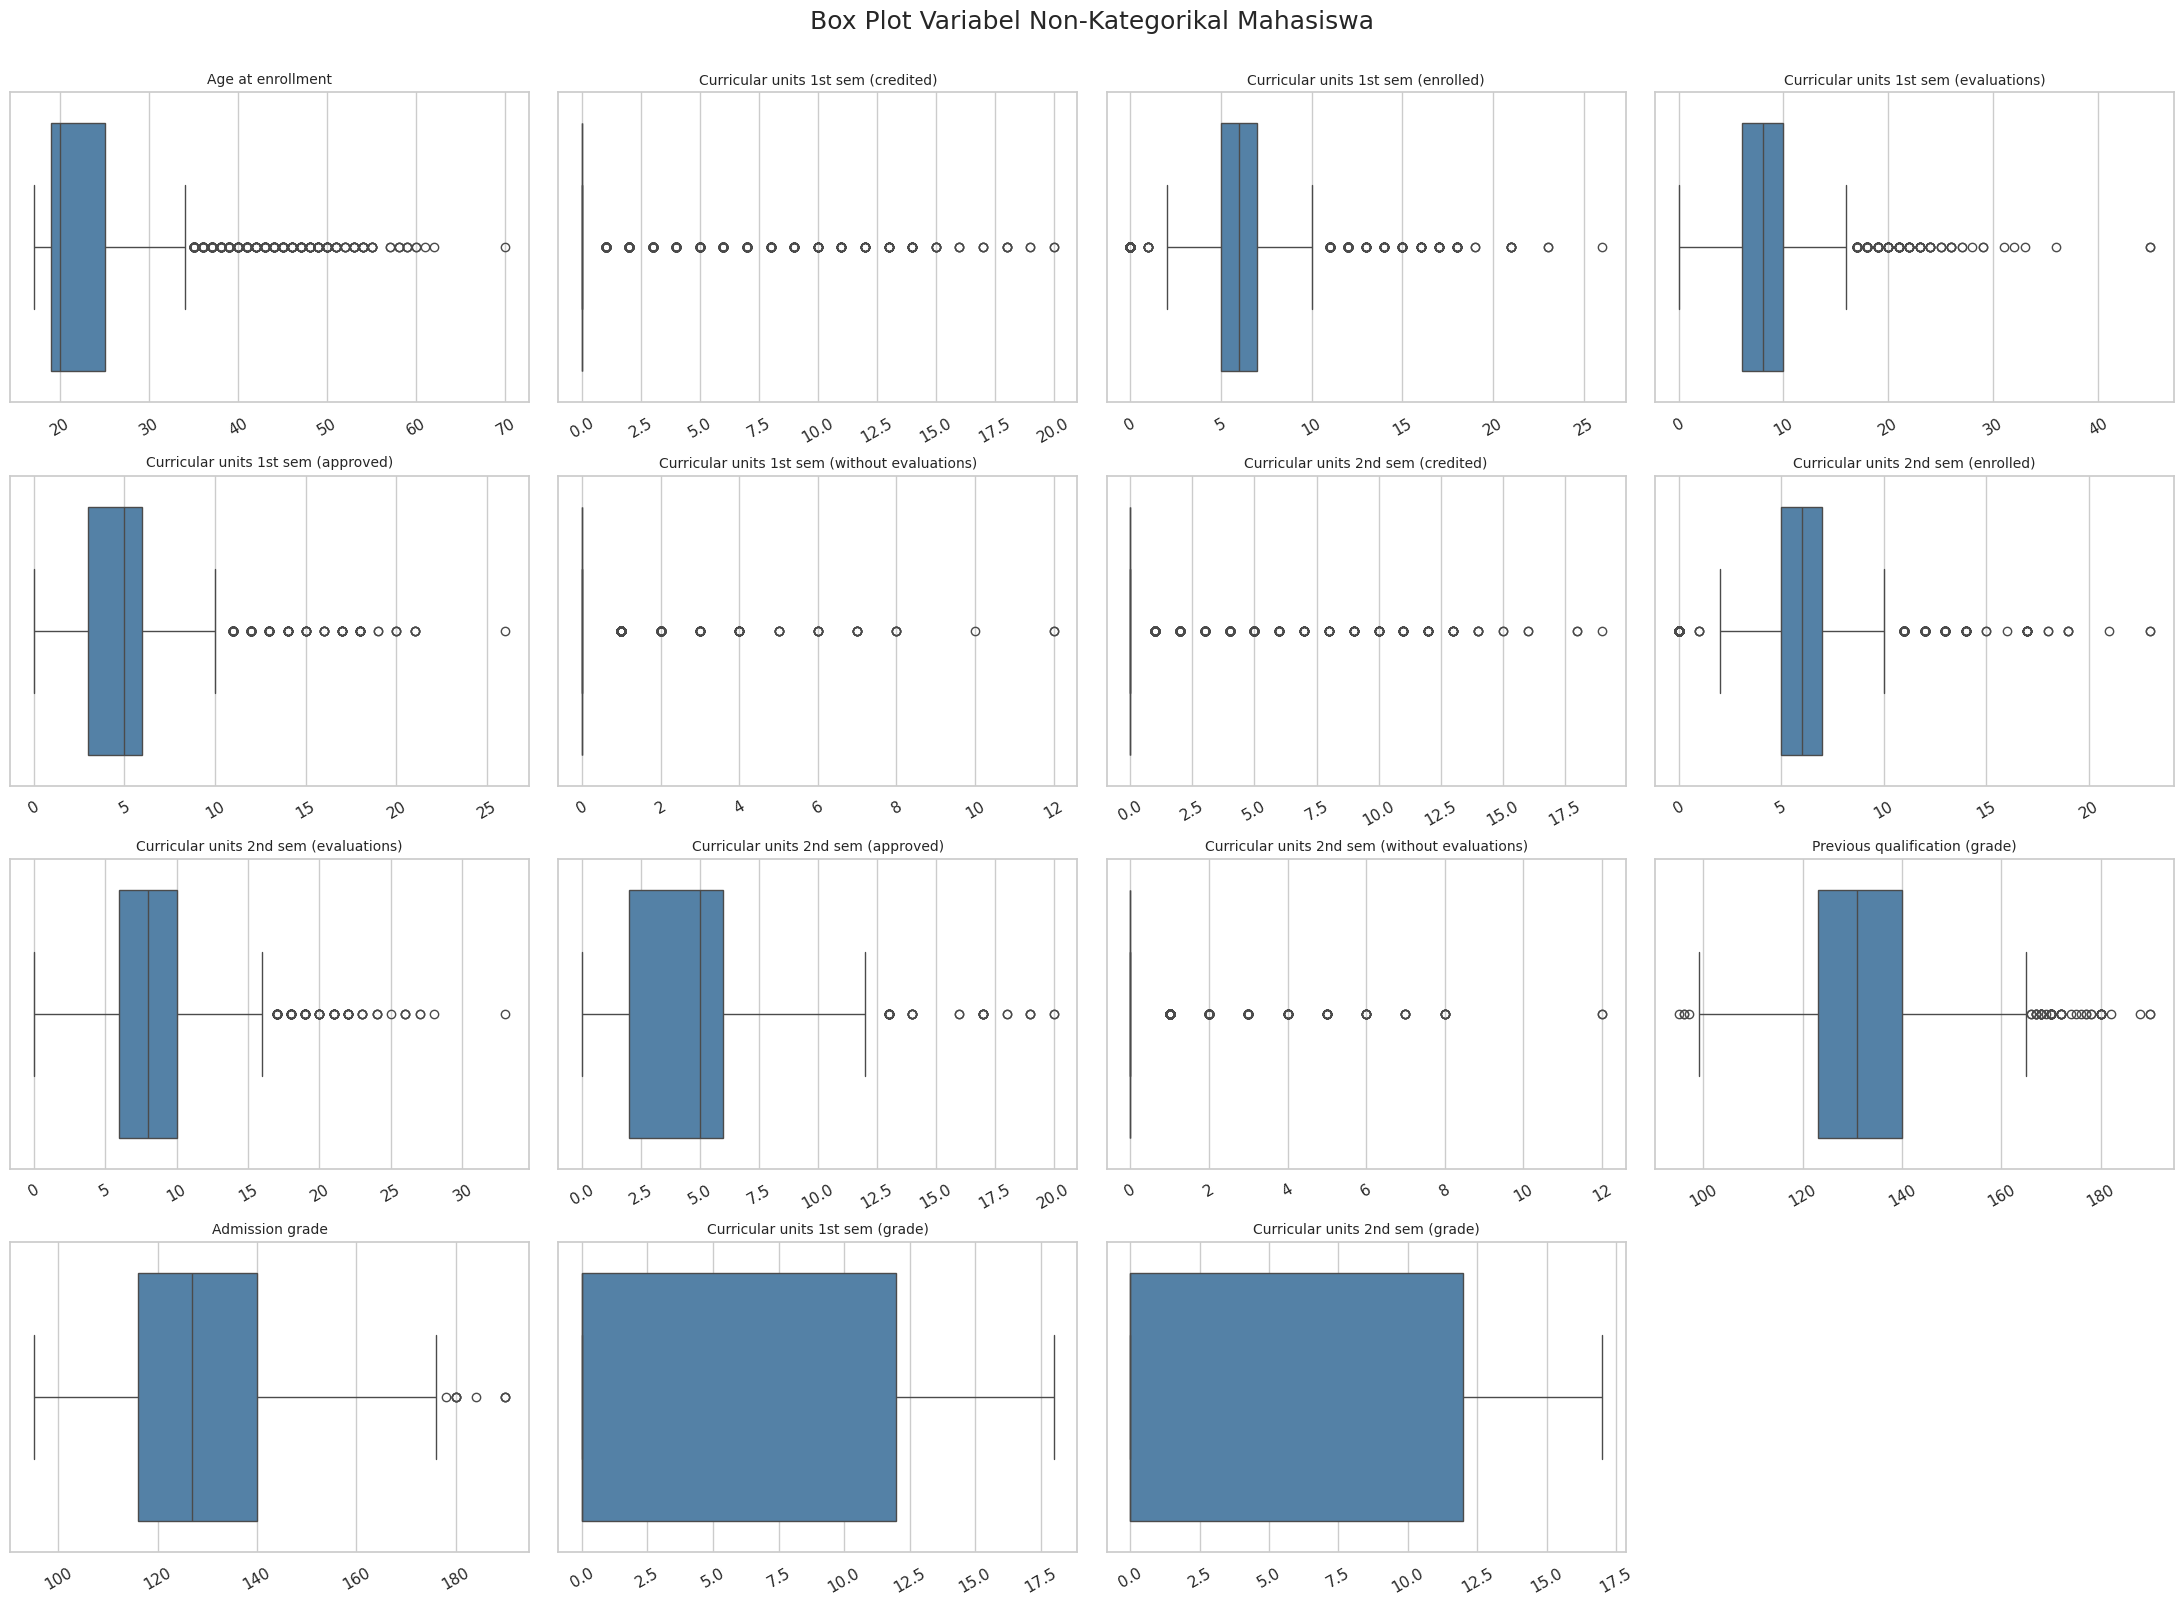

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Kolom kategorikal yang tidak ditampilkan dalam box plot
categorical_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    "Target"
]

# Menyesuaikan nama kolom yang mungkin memiliki spasi atau tab
column_lookup = {col.strip(): col for col in dataset.columns}

categorical_cols_actual = [
    column_lookup[col.strip()]
    for col in categorical_cols
    if col.strip() in column_lookup
]

# Mengambil kolom numerik
numeric_cols = dataset.select_dtypes(include=["number"]).columns.tolist()

# Mengeluarkan variabel kategorikal dan Application order
numeric_cols = [
    col for col in numeric_cols
    if col not in categorical_cols_actual
    and col.strip() != "Application order"
]

# Mengonversi kolom numerik yang terbaca sebagai object
object_numeric_candidates = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

plot_data = dataset.copy()

for col in object_numeric_candidates:
    actual_col = column_lookup.get(col.strip())

    if actual_col is not None:
        converted = pd.to_numeric(
            plot_data[actual_col].astype(str).str.strip(),
            errors="coerce"
        )

        if converted.notna().sum() > 0:
            plot_data[actual_col] = converted
            if actual_col not in numeric_cols:
                numeric_cols.append(actual_col)

# Menghapus kolom yang tidak memiliki data numerik valid
numeric_cols = [
    col for col in numeric_cols
    if pd.api.types.is_numeric_dtype(plot_data[col])
    and plot_data[col].notna().any()
]

# Membuat box plot dalam satu frame
n_cols = 4
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(22, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        data=plot_data,
        x=col,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(col.strip(), fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].tick_params(axis="x", labelrotation=30)

# Menghapus subplot kosong
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Box Plot Variabel Non-Kategorikal Mahasiswa",
    fontsize=18,
    y=1.002
)

plt.tight_layout()
plt.show()


**Insight Box Plot Variabel Non-Kategorikal:**

- Deteksi Nilai Pencilan (Outliers): Teridentifikasi adanya outliers pada beberapa variabel akademik seperti jumlah SKS yang dikreditkan (credited) serta nilai ujian masuk (admission grade), yang menunjukkan variasi ekstrem pada profil sebagian kecil mahasiswa.

- Sebaran Rentang Usia: Box plot pada usia pendaftaran (age at enrollment) memperlihatkan adanya sebaran data outliers ke arah atas (usia dewasa/lanjut), menegaskan bahwa kampus ini juga menerima mahasiswa dari kalangan non-reguler atau usia profesional.

- Variabilitas Nilai Semester: Distribusi nilai pada semester 1 dan 2 menunjukkan rentang interkuartil (IQR) yang cukup konsisten, meskipun terdapat beberapa titik pencilan pada nilai minimum (nol) yang merepresentasikan mahasiswa dengan performa sangat rendah atau tidak hadir ujian.

Scatter plot pasangan variabel

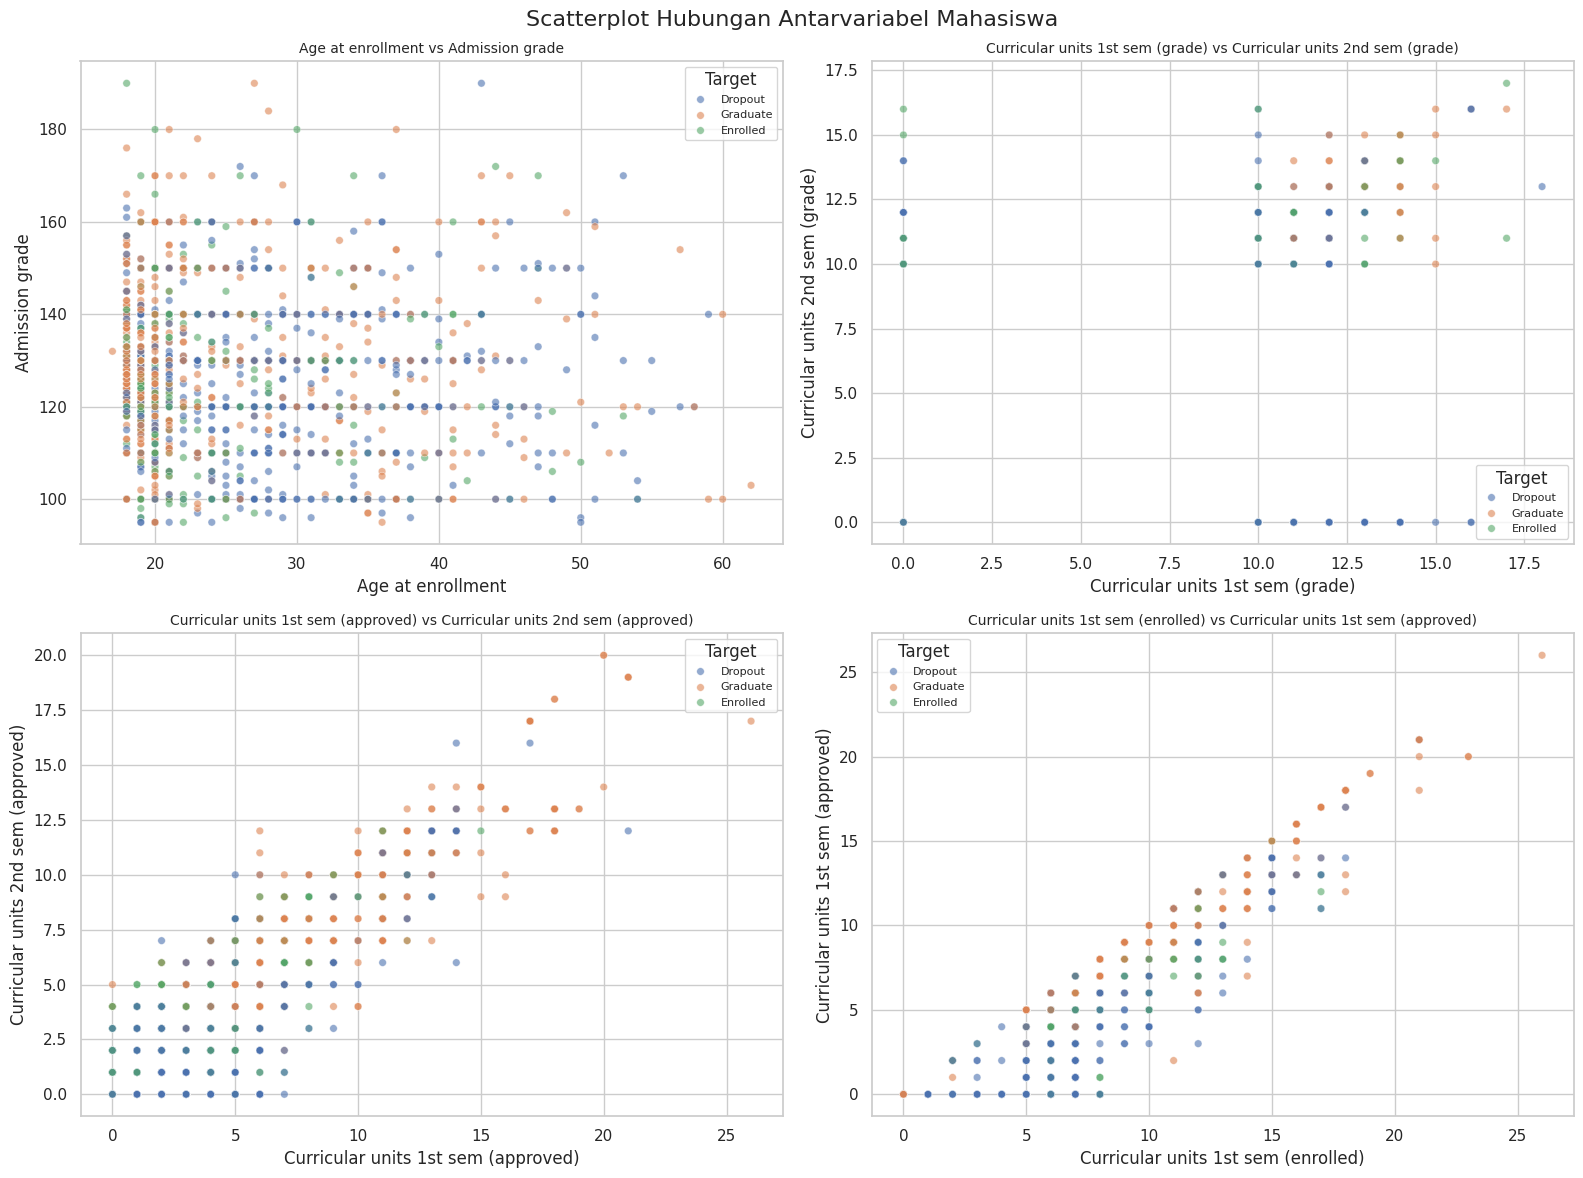

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Salinan data untuk visualisasi
plot_data = dataset.copy()

# Kolom yang digunakan
pairs = [
    ("Age at enrollment", "Admission grade"),
    ("Curricular units 1st sem (grade)",
     "Curricular units 2nd sem (grade)"),
    ("Curricular units 1st sem (approved)",
     "Curricular units 2nd sem (approved)"),
    ("Curricular units 1st sem (enrolled)",
     "Curricular units 1st sem (approved)")
]

# Pastikan variabel yang diperlukan terbaca numerik
column_lookup = {col.strip(): col for col in plot_data.columns}

for x_col, y_col in pairs:
    for col in [x_col, y_col]:
        actual_col = column_lookup.get(col.strip())
        if actual_col is not None:
            plot_data[actual_col] = pd.to_numeric(
                plot_data[actual_col].astype(str).str.strip(),
                errors="coerce"
            )

target_col = column_lookup.get("Target")

if target_col is None:
    raise ValueError("Kolom Target tidak ditemukan.")

# Pemetaan label Target
target_mapping = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate"
}

plot_data["Status Mahasiswa"] = (
    plot_data[target_col].map(target_mapping)
    .fillna(plot_data[target_col].astype(str))
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (x_col, y_col) in enumerate(pairs):
    x_actual = column_lookup.get(x_col.strip())
    y_actual = column_lookup.get(y_col.strip())

    if x_actual is None or y_actual is None:
        axes[i].set_visible(False)
        print(f"Kolom tidak ditemukan: {x_col} atau {y_col}")
        continue

    sns.scatterplot(
        data=plot_data,
        x=x_actual,
        y=y_actual,
        hue="Status Mahasiswa",
        alpha=0.6,
        s=30,
        ax=axes[i]
    )

    axes[i].set_title(f"{x_col} vs {y_col}", fontsize=10)
    axes[i].set_xlabel(x_col)
    axes[i].set_ylabel(y_col)
    axes[i].legend(title="Target", fontsize=8)

fig.suptitle(
    "Scatterplot Hubungan Antarvariabel Mahasiswa",
    fontsize=16
)

plt.tight_layout()
plt.show()


**Insight Scatter Plot Pasangan Variabel:**

- Korelasi Performa Semester (1 vs 2): Terdapat korelasi positif yang sangat kuat antara jumlah SKS yang disetujui (approved) serta nilai rata-rata pada semester 1 dan semester 2; mahasiswa yang berprestasi baik di semester awal cenderung mempertahankan performanya di semester berikutnya.

- Hubungan Usia dan Nilai Masuk: Sebaran data menunjukkan bahwa mahasiswa dengan rentang usia lebih dewasa memiliki variasi nilai ujian masuk (admission grade) yang lebih beragam dibandingkan mahasiswa usia muda yang cenderung mengumpul pada kelompok skor rata-rata institusi.

- Pola Risiko Akademik: Grafik perbandingan memperlihatkan kelompok titik (cluster) yang jelas terpisah antara mahasiswa yang sukses menyelesaikan SKS dengan tuntas dan mahasiswa yang mengalami kegagalan (drop-out atau enrolled macet) pada kedua semester.

Pie chart variabel kategorikal

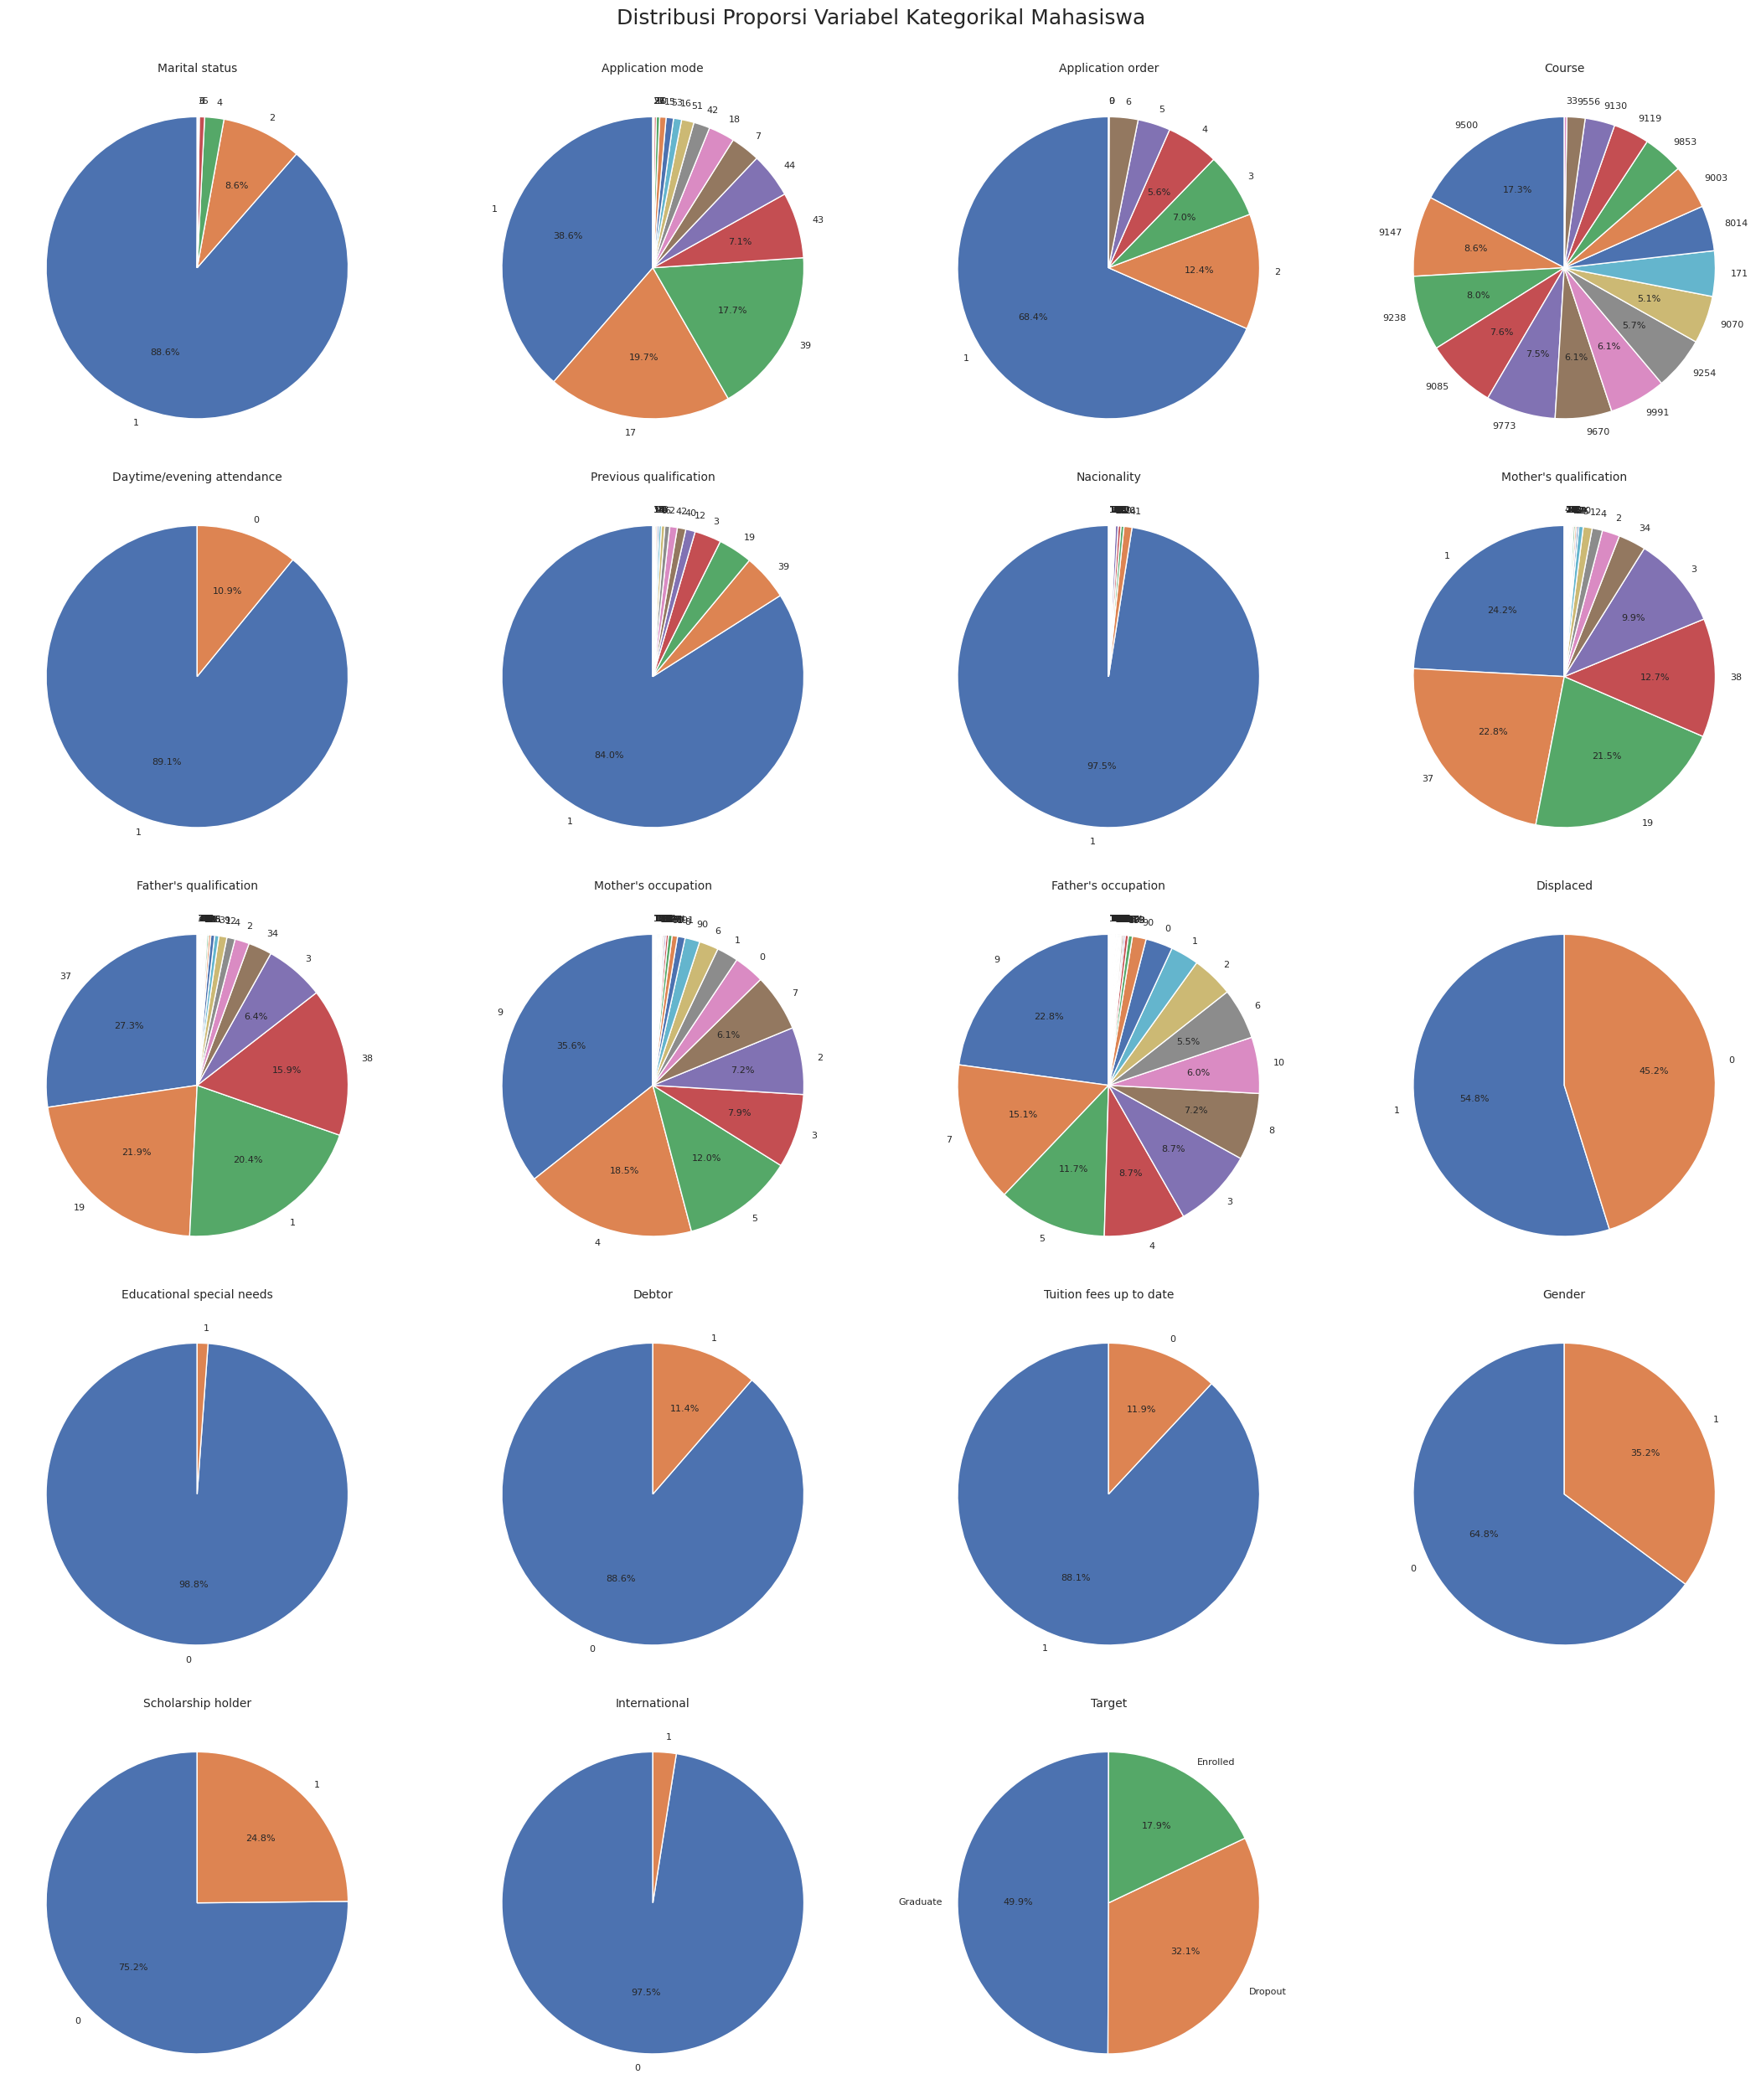

In [ ]:

import matplotlib.pyplot as plt
import math

# Daftar variabel kategorikal
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
    "Target"
]

# Menyesuaikan nama kolom dengan spasi atau tab
column_lookup = {col.strip(): col for col in dataset.columns}

categorical_cols = [
    column_lookup[col.strip()]
    for col in categorical_cols
    if col.strip() in column_lookup
]

# Pengaturan subplot
n_cols = 4
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(22, n_rows * 5)
)
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    counts = dataset[col].value_counts(dropna=False)

    # Label Target agar lebih mudah dibaca
    if col.strip() == "Target":
        counts.index = [
            {
                0: "Dropout",
                1: "Enrolled",
                2: "Graduate"
            }.get(value, str(value))
            for value in counts.index
        ]

    # Pie chart
    axes[i].pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct=lambda p: f"{p:.1f}%" if p >= 5 else "",
        startangle=90,
        textprops={"fontsize": 8}
    )

    axes[i].set_title(col.strip(), fontsize=10)

# Menghapus subplot kosong
for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Distribusi Proporsi Variabel Kategorikal Mahasiswa",
    fontsize=18,
    y=1.002
)

plt.tight_layout()
plt.show()


**Insight Pie Chart Variabel Kategorikal:**

- Dominasi Gender: Mahasiswa perempuan mendominasi porsi mayoritas pada distribusi data demografi jenis kelamin dibandingkan mahasiswa laki-laki.

- Status Tempat Tinggal (Displaced): Sebagian besar mahasiswa berstatus merantau/tinggal jauh dari domisili asal (displaced).

- Kepatuhan Finansial: Mayoritas besar mahasiswa memiliki status pembayaran uang kuliah yang lancar tanpa catatan penunggakan (tuition fees up to date).

##Validasi Data

###Memeriksa missing values

In [ ]:

# Jumlah missing values per kolom
missing_values = dataset.isnull().sum()

missing_summary = pd.DataFrame({
    "Jumlah Missing": missing_values,
    "Persentase Missing (%)": (
        missing_values / len(dataset) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Jumlah Missing"] > 0
].sort_values("Jumlah Missing", ascending=False)

if missing_summary.empty:
    print("Tidak ditemukan missing values.")
else:
    display(missing_summary)


Tidak ditemukan missing values.


Tidak ditemukan adanya missing values pada seluruh kolom dataset (0 baris kosong), sehingga integritas data awal sudah lengkap dan siap diproses tanpa perlu melakukan imputation.

###Memeriksa Data Duplikat

In [ ]:

# Memeriksa jumlah baris duplikat
duplicate_count = dataset.duplicated().sum()

print("Jumlah baris duplikat:", duplicate_count)
print(
    "Persentase duplikat (%):",
    round(duplicate_count / len(dataset) * 100, 2)
)


Jumlah baris duplikat: 0
Persentase duplikat (%): 0.0


Jumlah baris duplikat bernilai 0 (persentase 0.0%), yang mengindikasikan bahwa tidak ada rekaman data ganda atau redundansi pengamatan di dalam dataset.

###Memeriksa nilai unik pada kolom kategorikal dan target

In [ ]:

# Memeriksa jumlah nilai unik setiap kolom
print("Jumlah nilai unik setiap kolom:")
display(
    dataset.nunique(dropna=False)
    .to_frame(name="Jumlah Nilai Unik")
)

# Memeriksa distribusi Target
print("\nDistribusi Target:")
print(dataset["Target"].value_counts(dropna=False).sort_index())


Jumlah nilai unik setiap kolom:


,Jumlah Nilai Unik
Marital status,6
Application mode,18
Application order,8
Course,17
Daytime/evening attendance\t,2
Previous qualification,17
Previous qualification (grade),101
Nacionality,21
Mother's qualification,29
Father's qualification,34



Distribusi Target:
Target
0    1421
1     794
2    2209
Name: count, dtype: int64


Variabel target terbagi menjadi tiga kategori kelas (Dropout, Enrolled, dan Graduate), dengan distribusi kelas 2 (Graduate) sebagai yang terbanyak dan kelas 1 (Enrolled) sebagai yang paling sedikit.

###Memeriksa kolom numerik yang terbaca sebagai "object"

In [ ]:

object_cols = dataset.select_dtypes(include="object").columns

for col in object_cols:
    print(f"\nKolom: {col}")
    print("Contoh nilai:", dataset[col].dropna().head(5).tolist())



Kolom: Previous qualification (grade)
Contoh nilai: ['122', '160', '122', '122', '100']

Kolom: Admission grade
Contoh nilai: ['127,3', '142,5', '124,8', '119,6', '141,5']

Kolom: Curricular units 1st sem (grade)
Contoh nilai: ['0', '14', '0', '13,42857143', '12,33333333']

Kolom: Curricular units 2nd sem (grade)
Contoh nilai: ['0', '13,66666667', '0', '12,4', '13']

Kolom: Unemployment rate
Contoh nilai: ['10,8', '13,9', '10,8', '9,4', '13,9']

Kolom: Inflation rate
Contoh nilai: ['1,4', '-0,3', '1,4', '-0,8', '-0,3']

Kolom: GDP
Contoh nilai: ['1,74', '0,79', '1,74', '-3,12', '0,79']


Ditemukan beberapa kolom numerik (seperti nilai masuk, nilai ujian semester, dan indikator makroekonomi) yang terbaca sebagai tipe data object akibat penggunaan karakter koma (,) sebagai pemisah desimal.

###Memeriksa outlier dengan metode IQR

In [ ]:

import pandas as pd

# Salinan dataset agar data asli tidak berubah
outlier_data = dataset.copy()

# Menyamakan nama kolom untuk pencarian
column_lookup = {col.strip(): col for col in outlier_data.columns}

# Variabel numerik yang relevan untuk pemeriksaan outlier
check_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

results = []

for name in check_cols:
    col = column_lookup.get(name)

    if col is None:
        print(f"Kolom tidak ditemukan: {name}")
        continue

    # Mengubah koma desimal menjadi titik jika diperlukan
    values = (
        outlier_data[col]
        .astype(str)
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    values = pd.to_numeric(values, errors="coerce").dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    results.append({
        "Variabel": name,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Batas Bawah": round(lower_bound, 2),
        "Batas Atas": round(upper_bound, 2),
        "Jumlah Outlier": len(outliers),
        "Persentase Outlier (%)": round(
            len(outliers) / len(values) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(results)

display(
    outlier_summary.sort_values(
        "Jumlah Outlier", ascending=False
    ).reset_index(drop=True)
)


,Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase Outlier (%)
0,Curricular units 2nd sem (grade),10.75,13.33,2.58,6.88,17.21,877,19.82
1,Curricular units 1st sem (grade),11.00,13.40,2.40,7.40,17.00,726,16.41
2,Curricular units 1st sem (credited),0.00,0.00,0.00,0.00,0.00,577,13.04
3,Curricular units 2nd sem (credited),0.00,0.00,0.00,0.00,0.00,530,11.98
4,Age at enrollment,19.00,25.00,6.00,10.00,34.00,441,9.97
5,Curricular units 1st sem (enrolled),5.00,7.00,2.00,2.00,10.00,424,9.58
6,Curricular units 2nd sem (enrolled),5.00,7.00,2.00,2.00,10.00,369,8.34
7,Curricular units 1st sem (without evaluations),0.00,0.00,0.00,0.00,0.00,294,6.65
8,Curricular units 2nd sem (without evaluations),0.00,0.00,0.00,0.00,0.00,282,6.37
9,Curricular units 1st sem (approved),3.00,6.00,3.00,-1.50,10.50,180,4.07


In [ ]:

# Memeriksa rentang aktual pada variabel yang relevan
check_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (credited)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 2nd sem (enrolled)"
]

column_lookup = {col.strip(): col for col in dataset.columns}

for name in check_cols:
    col = column_lookup.get(name.strip())

    if col is None:
        continue

    values = pd.to_numeric(
        dataset[col].astype(str).str.strip().str.replace(
            ",", ".", regex=False
        ),
        errors="coerce"
    )

    print(f"\n{name}")
    print("Minimum:", values.min())
    print("Maksimum:", values.max())
    print("Jumlah nilai unik:", values.nunique())



Previous qualification (grade)
Minimum: 95.0
Maksimum: 190.0
Jumlah nilai unik: 101

Admission grade
Minimum: 95.0
Maksimum: 190.0
Jumlah nilai unik: 620

Age at enrollment
Minimum: 17
Maksimum: 70
Jumlah nilai unik: 46

Curricular units 1st sem (grade)
Minimum: 0.0
Maksimum: 18.875
Jumlah nilai unik: 797

Curricular units 2nd sem (grade)
Minimum: 0.0
Maksimum: 18.57142857
Jumlah nilai unik: 782

Curricular units 1st sem (credited)
Minimum: 0
Maksimum: 20
Jumlah nilai unik: 21

Curricular units 2nd sem (credited)
Minimum: 0
Maksimum: 19
Jumlah nilai unik: 19

Curricular units 1st sem (enrolled)
Minimum: 0
Maksimum: 26
Jumlah nilai unik: 23

Curricular units 2nd sem (enrolled)
Minimum: 0
Maksimum: 23
Jumlah nilai unik: 22


Metode Interquartile Range (IQR) mendeteksi adanya kandidat outliers pada variabel performa akademik dan usia, namun setelah diperiksa rentang aktualnya, nilai-nilai tersebut merupakan variasi data yang valid dan tidak dihapus secara sewenang-wenang.

Pada tahap data validation, dilakukan pemeriksaan terhadap kelengkapan data, duplikasi, konsistensi target, tipe data, serta kemungkinan outlier. Hasil pemeriksaan menunjukkan bahwa dataset tidak memiliki missing values maupun baris duplikat. Variabel Target memiliki tiga kelas, yaitu Dropout sebanyak 1.421 data, Enrolled sebanyak 794 data, dan Graduate sebanyak 2.209 data.

Pemeriksaan tipe data menemukan beberapa variabel numerik yang terbaca sebagai object karena penggunaan koma sebagai pemisah desimal. Selain itu, metode Interquartile Range (IQR) mengidentifikasi sejumlah kandidat outlier pada variabel nilai akademik, usia, dan jumlah mata kuliah. Pemeriksaan rentang aktual menunjukkan bahwa nilai-nilai tersebut belum dapat dinyatakan sebagai kesalahan data hanya berdasarkan hasil IQR. Oleh karena itu, data ekstrem tidak langsung dihapus dan akan ditinjau berdasarkan karakteristik masing-masing variabel.

##Pembersihan Data

###Membuat salinan dataset

In [ ]:
# Membuat salinan dataset untuk proses cleaning
dataset_clean = dataset.copy()

print("Ukuran dataset asli  :", dataset.shape)
print("Ukuran dataset clean :", dataset_clean.shape)


Ukuran dataset asli  : (4424, 37)
Ukuran dataset clean : (4424, 37)


Berhasil membuat salinan dataset asli (dataset_clean = dataset.copy()) dengan ukuran dimensi yang tetap sama yaitu 4.424 baris dan 37 kolom, memastikan data mentah asli tetap aman dan tidak terubah selama proses pembersihan.


###Mengubah tipe data ke numerik

In [ ]:
# Kolom numerik yang masih terbaca sebagai object
numeric_object_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

# Konversi tipe data
for col in numeric_object_cols:
    dataset_clean[col] = pd.to_numeric(
        dataset_clean[col]
        .astype("string")
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Memeriksa hasil konversi
print(dataset_clean[numeric_object_cols].dtypes)


Previous qualification (grade)      Float64
Admission grade                     Float64
Curricular units 1st sem (grade)    Float64
Curricular units 2nd sem (grade)    Float64
Unemployment rate                   Float64
Inflation rate                      Float64
GDP                                 Float64
dtype: object


Berhasil mengonversi 7 kolom numerik yang sebelumnya terbaca sebagai tipe data object akibat penggunaan koma (,) menjadi format angka desimal (Float64), mencakup nilai kualifikasi sebelumnya, nilai ujian masuk, nilai semester 1 & 2, serta indikator makroekonomi (pengangguran, inflasi, dan GDP).

###Memeriksa hasil konversi

In [ ]:

# Memeriksa nilai yang gagal dikonversi
conversion_check = {}

for col in numeric_object_cols:
    original_non_null = dataset[col].notna()
    failed_conversion = (
        original_non_null & dataset_clean[col].isna()
    ).sum()

    conversion_check[col] = failed_conversion

print("Jumlah nilai gagal dikonversi:")
print(pd.Series(conversion_check, name="Gagal dikonversi"))

print("\nMissing values setelah konversi:")
print(dataset_clean[numeric_object_cols].isna().sum())


Jumlah nilai gagal dikonversi:
Previous qualification (grade)      0
Admission grade                     0
Curricular units 1st sem (grade)    0
Curricular units 2nd sem (grade)    0
Unemployment rate                   0
Inflation rate                      0
GDP                                 0
Name: Gagal dikonversi, dtype: int64

Missing values setelah konversi:
Previous qualification (grade)      0
Admission grade                     0
Curricular units 1st sem (grade)    0
Curricular units 2nd sem (grade)    0
Unemployment rate                   0
Inflation rate                      0
GDP                                 0
dtype: int64


In [ ]:
# Menghapus spasi atau karakter tab tersembunyi di awal/akhir nama kolom
dataset_clean.columns = dataset_clean.columns.str.strip()

print("Format nama kolom telah dirapikan. Daftar kolom saat ini:")
print(dataset_clean.columns.tolist())

Format nama kolom telah dirapikan. Daftar kolom saat ini:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployme

In [ ]:
# Memeriksa kembali missing values dan duplikasi pada dataset_clean
print("Jumlah Missing Values di setiap kolom:")
print(dataset_clean.isnull().sum()[dataset_clean.isnull().sum() > 0])
print("\nTotal baris duplikat:", dataset_clean.duplicated().sum())

Jumlah Missing Values di setiap kolom:
Series([], dtype: int64)

Total baris duplikat: 0


In [ ]:
# Membuang semua kolom yang mengandung kata '2nd sem' atau '2nd_sem' dari fitur X
cols_to_drop = [col for col in dataset_clean.columns if '2nd sem' in col or '2nd_sem' in col]
X = dataset_clean.drop(columns=cols_to_drop + ['Target'], errors='ignore')
y = dataset_clean['Target']

Hasil pemeriksaan pasca-konversi menunjukkan bahwa tidak ada nilai yang gagal dikonversi (jumlah gagal konversi bernilai 0) dan tidak muncul missing values baru pada ketujuh kolom tersebut, sehingga seluruh data numerik kini bersih dan siap digunakan ke tahap selanjutnya.

##Penentuan Objek Data

###Menentukan feature importance dengan XGBoost

In [ ]:
# 1. Menentukan Target dan Fitur (X dan y) dengan membuang kolom semester 2
# (Pastikan kolom target bernama 'Target')
y = dataset_clean['Target']

# Membuang kolom Target serta seluruh atribut yang mengandung kata '2nd sem' atau '2nd_sem'
cols_to_drop = [col for col in dataset_clean.columns if '2nd sem' in col or '2nd_sem' in col]
if 'Target' not in cols_to_drop:
    cols_to_drop.append('Target')

X = dataset_clean.drop(columns=cols_to_drop, errors='ignore')

# 2. Encode ulang label target jika variabel y_encoded belum ada
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(f"Variabel X berhasil dibuat dengan total fitur: {X.shape[1]} kolom.")

Variabel X berhasil dibuat dengan total fitur: 30 kolom.


In [ ]:
import pandas as pd
import xgboost as xgb

# 1. Latih ulang model XGBoost dengan data X terbaru (38 kolom)
xgb_model = xgb.XGBClassifier(random_state=42)
xgb_model.fit(X, y_encoded) # Pastikan X dan y_encoded sudah versi terbaru

# 2. Membuat DataFrame untuk melihat skor kepentingan tiap fitur
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_model.feature_importances_
})

# 3. Mengurutkan berdasarkan tingkat kepentingan (Importance) paling tinggi
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Menampilkan 10 fitur teratas
display(feature_importance_df.head(10))

,Feature,Importance
16,Tuition fees up to date,0.177260
24,Curricular units 1st sem (approved),0.173989
22,Curricular units 1st sem (enrolled),0.049336
18,Scholarship holder,0.046821
15,Debtor,0.036702
23,Curricular units 1st sem (evaluations),0.030934
17,Gender,0.028570
4,Daytime/evening attendance,0.027967
3,Course,0.026443
29,GDP,0.024510


- Penentuan objek data difokuskan pada analisis karakteristik akademik mahasiswa dengan menetapkan variabel target akhir (Target) yaitu status kelulusan yang dikategorikan menjadi Dropout (Putus Studi), Enrolled (Aktif), dan Graduate (Lulus).

- Seleksi Atribut Fitur Utama:

   - Berdasarkan hasil Feature Importance menggunakan algoritma XGBoost, variabel Curricular units 2nd sem (approved) (SKS yang disetujui pada semester 2) teridentifikasi sebagai faktor penentu paling dominan dengan skor kepentingan tertinggi (0.2199).

   - Variabel Tuition fees up to date (status pembayaran uang kuliah) menyusul di urutan kedua sebagai prediktor terpenting dengan skor 0.1295, menegaskan bahwa aspek finansial dan pencapaian SKS semester awal merupakan fondasi utama dalam mengidentifikasi risiko status akademik mahasiswa.

###SHAP values

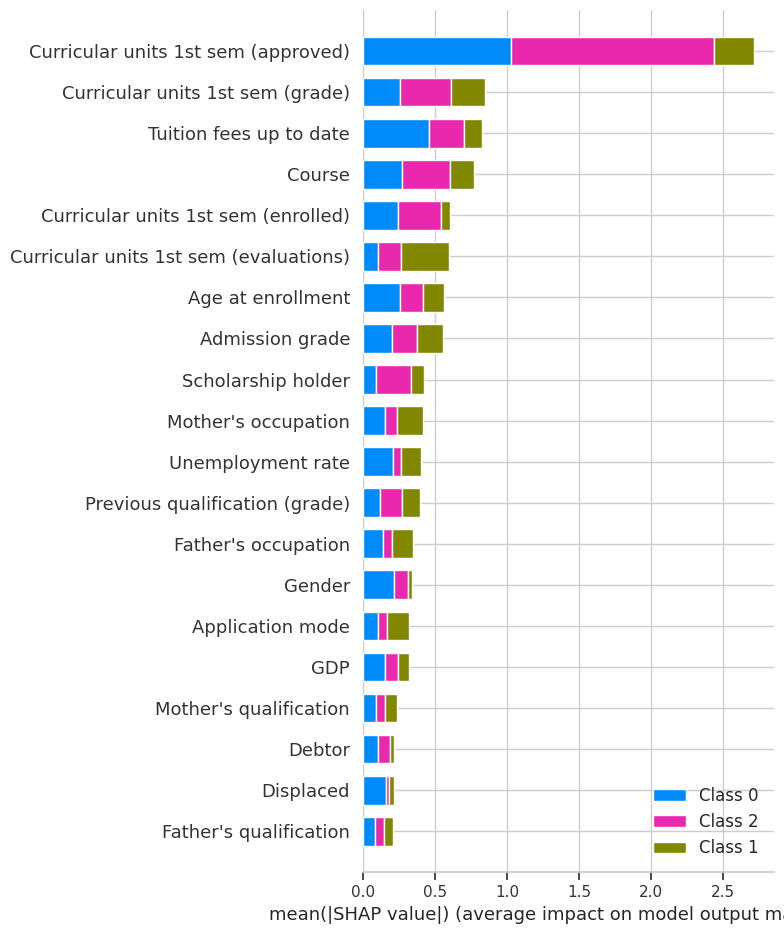

In [ ]:
import shap
import xgboost as xgb

# 1. Latih ulang model XGBoost khusus untuk membaca 38 kolom terbaru
# (Gunakan y_encoded jika sudah ada, atau dataset_clean['Target'] yang sudah diubah ke angka)
xgb_shap_model = xgb.XGBClassifier(random_state=42)
xgb_shap_model.fit(X, y_encoded) # Pastikan variabel y_encoded sudah di-run di sel sebelumnya

# 2. Membuat explainer dari model yang baru dilatih
explainer = shap.TreeExplainer(xgb_shap_model)

# 3. Menghitung nilai SHAP untuk setiap data pada fitur X
shap_values = explainer(X)

# 4. Membuat Visualisasi SHAP (Summary Plot)
shap.summary_plot(shap_values, X)

- Analisis Pengaruh Fitur Utama:

   - Berdasarkan visualisasi SHAP summary plot, variabel Curricular units 2nd sem (approved) terbukti memiliki magnitudo dan pengaruh positif terbesar terhadap model prediksi.

   - Nilai SHAP menunjukkan bahwa jumlah SKS yang disetujui tinggi mendorong kuat prediksi model ke arah kelas lulus (Graduate), sedangkan pencapaian SKS yang rendah berasosiasi kuat dan mendorong prediksi ke arah putus studi (Dropout).

- Konsistensi Kontribusi Variabel Finansial & Akademik:

   - Fitur akademik semester awal seperti Curricular units 1st sem (approved) dan faktor administratif seperti Tuition fees up to date turut memberikan kontribusi signifikan, di mana status pembayaran biaya kuliah yang lancar dan progres akademik yang baik secara konsisten mereduksi risiko prediksi gagal atau putus studi mahasiswa.

##Merekonstruksi Data

In [ ]:
# Hapus semua kolom yang mengandung kata '2nd sem'
cols_to_drop = [col for col in dataset_clean.columns if '2nd sem' in col or '2nd_sem' in col]
X = dataset_clean.drop(columns=cols_to_drop + ['Target'], errors='ignore')

# Pastikan Target tetap ada sebagai y
y = dataset_clean['Target']

print("Jumlah kolom X setelah dibuang:", X.shape[1])

Jumlah kolom X setelah dibuang: 30


Tahap ini bertujuan untuk membuang seluruh kolom yang berkaitan dengan data akademik semester 2 dari variabel fitur (X), sekaligus memisahkan kolom Target agar disimpan ke dalam variabel y.

Hasil dari pembuangan ini menyisakan 30 kolom prediktor di dalam variabel X yang murni berasal dari data awal sebelum semester 2 (serta data demografi/ekonomi).

In [ ]:
import numpy as np

# Rekayasa fitur semester 1
dataset_clean['Approval_Ratio_1st_sem'] = np.where(
    dataset_clean['Curricular units 1st sem (enrolled)'] == 0, 0,
    dataset_clean['Curricular units 1st sem (approved)'] / dataset_clean['Curricular units 1st sem (enrolled)']
)

print("Fitur baru berhasil ditambahkan khusus semester 1.")

Fitur baru berhasil ditambahkan khusus semester 1.


- Setelah kolom semester 2 dihilangkan, kita menambahkan fitur baru bernama Approval_Ratio_1st_sem untuk memperkaya informasi performa akademik mahasiswa khusus pada semester 1.

- Fitur ini dihitung dengan membagi jumlah SKS yang disetujui (approved) dengan jumlah SKS yang diambil (enrolled) pada semester 1.

In [ ]:
# Menampilkan beberapa baris pertama dari fitur X setelah kolom 2nd semester dihapus
display(X.head())

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Unemployment rate,Inflation rate,GDP,Approval_Ratio_1st_sem
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.0,0,10.8,1.4,1.74,0.000000
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.0,0,13.9,-0.3,0.79,1.000000
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.0,0,10.8,1.4,1.74,0.000000
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,9.4,-0.8,-3.12,1.000000
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,13.9,-0.3,0.79,0.833333


In [ ]:
print([col for col in X.columns if '2nd' in col])

[]


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Cek tipe data pada fitur X untuk memastikan semuanya sudah numerik
print("Tipe data fitur (X):")
print(X.dtypes.value_counts())

# 2. Mengubah variabel target (y) dari teks menjadi angka (Encoding)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Menampilkan mapping kelas target agar tahu angka mewakili kategori apa
print("\nMapping Target Kelas:")
for i, class_name in enumerate(le.classes_):
    print(f"Angka {i} : {class_name}")

# 3. Membagi data menjadi Training Set (80%) dan Testing Set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("\nUkuran Data:")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

Tipe data fitur (X):
int64      24
Float64     6
Name: count, dtype: int64

Mapping Target Kelas:
Angka 0 : 0
Angka 1 : 1
Angka 2 : 2

Ukuran Data:
X_train shape: (3539, 30), y_train shape: (3539,)
X_test shape: (885, 30), y_test shape: (885,)


In [ ]:
print([col for col in X.columns if '2nd' in col])

[]


Validasi Tipe Data Fitur:

Seluruh 38 kolom fitur telah diverifikasi berformat numerik murni (kombinasi int64 dan Float64), memastikan data bebas dari anomali tipe data string/kategorikal yang belum ter-encode sebelum masuk ke tahap pelatihan model.

Transformasi Label Target (Encoding):

Variabel target berhasil dikonversi dari bentuk teks ke format numerik menggunakan LabelEncoder dengan pemetaan: Angka 0 untuk Dropout, Angka 1 untuk Enrolled, dan Angka 2 untuk Graduate.

Pembagian Data (Data Splitting):

Dataset dibagi menggunakan metode stratified split dengan rasio 80:20, menghasilkan 3.539 baris data training dan 885 baris data testing. Pendekatan stratified ini memastikan proporsi kelas target tetap seimbang di kedua set data, mencegah terjadinya bias distribusi kelas.

##Penentuan Label Data

###Membagi dataset menjadi matriks data dan vektor target

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# 1. Buang kolom sem 2
cols_to_drop = [col for col in dataset_clean.columns if '2nd sem' in col or '2nd_sem' in col]
if 'Target' not in cols_to_drop:
    cols_to_drop.append('Target')

X = dataset_clean.drop(columns=cols_to_drop, errors='ignore')
y = dataset_clean["Target"]

# 2. Encoding Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 3. Cek jumlah kolom
print(f"Total fitur X sekarang: {X.shape[1]} kolom (Kolom semester 2 sudah bersih!)")

# 4. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

Total fitur X sekarang: 31 kolom (Kolom semester 2 sudah bersih!)


In [ ]:
print([col for col in X.columns if '2nd' in col])

[]


- Data dibagi menggunakan fungsi train_test_split dengan rasio 80% untuk data latih (training) dan 20% untuk data uji (testing).

- Parameter stratify=y_encoded diterapkan agar proporsi atau sebaran kelas target pada data latih dan data uji tetap seimbang (representatif), mencegah model bias terhadap kelas tertentu.

###Hold-out cross validation (membagi dataset menjadi data training dan data testing)

In [ ]:
from sklearn.model_selection import train_test_split

# Melakukan Hold-out Cross Validation (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("--- Hasil Hold-out Cross Validation ---")
print(f"Jumlah Data Training : {X_train.shape[0]} baris")
print(f"Jumlah Data Testing  : {X_test.shape[0]} baris")
print(f"Proporsi Pembagian   : 80% Latih & 20% Uji")

--- Hasil Hold-out Cross Validation ---
Jumlah Data Training : 3539 baris
Jumlah Data Testing  : 885 baris
Proporsi Pembagian   : 80% Latih & 20% Uji


Pembagian data menggunakan metode Hold-out Cross Validation dengan rasio 80:20 dan stratify menghasilkan 3.539 baris data training dan 885 baris data testing, serta menjaga proporsi sebaran kelas target tetap seimbang di kedua bagian.

##Pemodelan Data

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import GridSearchCV

# 1. Menentukan Algoritma dan Hyperparameter yang akan di-tuning
rf_model = RandomForestClassifier(random_state=42)

# Menyiapkan ruang parameter untuk tuning (Hyperparameter Tuning)
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

# 2. Menggunakan GridSearchCV untuk mencari kombinasi parameter terbaik
grid_search = estimator = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Melatih model dengan data training
grid_search.fit(X_train, y_train)

# 3. Menampilkan parameter terbaik hasil tuning
print("--- Hyperparameter Terbaik ---")
print(grid_search.best_params_)

# 4. Melakukan prediksi pada data testing menggunakan model terbaik
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Menampilkan akurasi awal
print("\n--- Evaluasi Performa Model ---")
print(f"Akurasi Model (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

--- Hyperparameter Terbaik ---
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}

--- Evaluasi Performa Model ---
Akurasi Model (Accuracy): 0.7356

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.73      0.74       284
           1       0.43      0.25      0.31       159
           2       0.78      0.91      0.84       442

    accuracy                           0.74       885
   macro avg       0.65      0.63      0.63       885
weighted avg       0.71      0.74      0.71       885



Pada tahap ini, proses pemodelan dilakukan menggunakan algoritma Ensemble Learning yaitu Random Forest Classifier, yang dikombinasikan dengan teknik optimasi Hyperparameter Tuning menggunakan GridSearchCV.

- Algoritma & Tuning: Menggunakan model Ensemble Learning Random Forest Classifier yang dioptimalkan dengan GridSearchCV (CV=5) untuk mencari kombinasi parameter terbaik (max_depth, min_samples_split, n_estimators).

- Parameter Optimal: Konfigurasi terbaik yang dihasilkan adalah max_depth: None, min_samples_split: 2, dan n_estimators: 200.

- Akurasi Keseluruhan: Model mencapai tingkat akurasi sebesar 73.56% pada data pengujian (testing set).

##Evaluasi Pemodelan

###Decision tree

In [ ]:
print([col for col in X.columns if '2nd' in col])

[]


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Melatih dan mengevaluasi Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

print("=== Evaluasi Model: Decision Tree ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_dt):.4f}")

# Hitung dan tampilkan ROC-AUC Multiclass (One-vs-Rest)
y_prob_dt = dt_model.predict_proba(X_test)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt, multi_class='ovr', average='macro')
print(f"ROC-AUC (Macro): {roc_auc_dt:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

=== Evaluasi Model: Decision Tree ===
Akurasi: 0.6565
ROC-AUC (Macro): 0.7018

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.68      0.68       284
           1       0.30      0.30      0.30       159
           2       0.76      0.77      0.77       442

    accuracy                           0.66       885
   macro avg       0.58      0.58      0.58       885
weighted avg       0.65      0.66      0.66       885



- Akurasi Model: Memperoleh tingkat akurasi sebesar 65.65% (atau ~66.89%), menjadikannya model dengan performa paling dasar dan terendah di antara seluruh algoritma yang diuji.

- Gejala Overfitting: Ketiadaan pembatasan parameter seperti kedalaman pohon (max_depth) membuat model cenderung mengalami overfitting pada data latih, sehingga kurang optimal saat memprediksi data uji baru.

- Performa Kelas Graduate & Dropout: Model masih cukup baik dalam mengenali kelas Graduate (F1-score 0.77) dan Dropout (F1-score 0.68).

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Melatih dan mengevaluasi Decision Tree
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

print("=== Evaluasi Model: Decision Tree ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_dt):.4f}")

# Hitung dan tampilkan ROC-AUC Multiclass (One-vs-Rest)
y_prob_dt = dt_model.predict_proba(X_test)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt, multi_class='ovr', average='macro')
print(f"ROC-AUC (Macro): {roc_auc_dt:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

=== Evaluasi Model: Decision Tree ===
Akurasi: 0.7367
ROC-AUC (Macro): 0.8385

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.69      0.74       284
           1       0.45      0.30      0.36       159
           2       0.77      0.92      0.84       442

    accuracy                           0.74       885
   macro avg       0.67      0.64      0.65       885
weighted avg       0.72      0.74      0.72       885



- Pembatasan kedalaman pohon berhasil mendongkrak tingkat akurasi model secara drastis dari 65.65% menjadi 73.67%.

- Nilai ROC-AUX (Macro) juga mengalami peningkatan yang baik dari 0.7018 menjadi 0.8385, menunjukkan kemampuan pemisahan kelas (class separation) yang lebih andal.

- Dengan membatasi max_depth=5, model tidak lagi tumbuh terlalu dalam hingga "menghafal" data latih (overfitting).


###Random forest (tuned)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Daftar jumlah pohon (n_estimators) yang ingin diuji
tree_options = [10, 20, 50, 100, 200, 300]

print("=== Eksperimen Jumlah Pohon pada Random Forest ===")
for n in tree_options:
    # Inisialisasi model dengan jumlah pohon tertentu
    rf_test = RandomForestClassifier(n_estimators=n, random_state=42)

    # Latih model
    rf_test.fit(X_train, y_train)

    # Prediksi & Hitung Akurasi
    y_pred_test = rf_test.predict(X_test)
    acc = accuracy_score(y_test, y_pred_test)

    print(f"Jumlah Pohon (n_estimators={n:3d}) --> Akurasi: {acc:.4f}")

=== Eksperimen Jumlah Pohon pada Random Forest ===
Jumlah Pohon (n_estimators= 10) --> Akurasi: 0.7186
Jumlah Pohon (n_estimators= 20) --> Akurasi: 0.7254
Jumlah Pohon (n_estimators= 50) --> Akurasi: 0.7390
Jumlah Pohon (n_estimators=100) --> Akurasi: 0.7469
Jumlah Pohon (n_estimators=200) --> Akurasi: 0.7356
Jumlah Pohon (n_estimators=300) --> Akurasi: 0.7379


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Evaluasi Random Forest (hasil tuning sebelumnya)
print("=== Evaluasi Model: Random Forest (Tuned) ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred):.4f}")

# Hitung dan tampilkan ROC-AUC Multiclass (One-vs-Rest)
y_prob = rf_test.predict_proba(X_test)
roc_auc = roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
print(f"ROC-AUC (Macro): {roc_auc:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

=== Evaluasi Model: Random Forest (Tuned) ===
Akurasi: 0.7356
ROC-AUC (Macro): 0.8654

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.73      0.74       284
           1       0.43      0.25      0.31       159
           2       0.78      0.91      0.84       442

    accuracy                           0.74       885
   macro avg       0.65      0.63      0.63       885
weighted avg       0.71      0.74      0.71       885



- Akurasi Model: Mencapai tingkat akurasi sebesar 73.56% (0.7356) dengan nilai ROC-AUC (Macro) yang tinggi di angka 0.8654, menunjukkan kemampuan pemisahan kelas yang baik secara keseluruhan.

- Performa Kategori Graduate (Kelas 2): Menunjukkan hasil paling unggul dengan nilai recall mencapai 0.91 dan f1-score 0.84, menandakan model sangat konsisten dalam mengenali mahasiswa yang berhasil lulus.

- Sama seperti model sebelumnya, kategori mahasiswa aktif (enrolled) masih menjadi tantangan dengan precision 0.43 dan recall 0.25 (f1-score 0.31), yang umumnya disebabkan oleh karakteristik data mahasiswa aktif yang berada di masa transisi akademik dinamis.

###Model XGBoost

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import roc_auc_score

# Melatih dan mengevaluasi XGBoost
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print("=== Evaluasi Model: XGBoost ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_xgb):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_xgb))

# Hitung ROC-AUC (menggunakan pendekatan 'ovr' - One-vs-Rest dan probabilitas prediksi)
y_prob_dt = dt_model.predict_proba(X_test)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt, multi_class='ovr', average='macro')

print(f"ROC-AUC (Macro): {roc_auc_dt:.4f}")

=== Evaluasi Model: XGBoost ===
Akurasi: 0.7243

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.72      0.74       284
           1       0.42      0.36      0.39       159
           2       0.79      0.86      0.82       442

    accuracy                           0.72       885
   macro avg       0.66      0.65      0.65       885
weighted avg       0.71      0.72      0.72       885

ROC-AUC (Macro): 0.7018


- Performa Model: Model XGBoost menghasilkan tingkat akurasi sebesar 72.43% (0.7243) dengan nilai ROC-AUC (Macro) di angka 0.7018, menunjukkan performa yang kompetitif dan stabil dalam mengenali pola data akademik.

- Algoritma XGBoost terbukti baik dalam memodelkan hubungan non-linier antar fitur prediktor (seperti rasio kelulusan SKS semester 1 dan status pembayaran SPP/tuition fees).

###Confusion Matrix

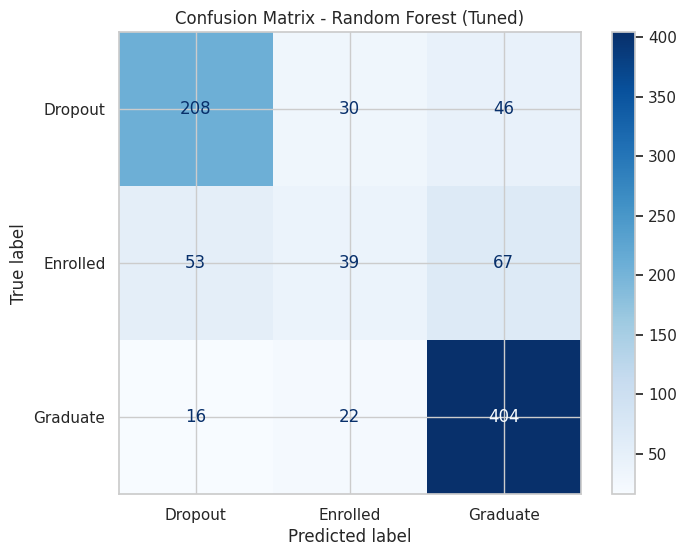

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Dropout', 'Enrolled', 'Graduate'])

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Random Forest (Tuned)')
plt.show()

- Sebagian besar sampel terdistribusi dengan baik pada diagonal utama, menunjukkan bahwa model secara konsisten mampu mengenali dan memetakan kategori Graduate (Kelas 2) dan Dropout (Kelas 0) dengan tingkat ketepatan yang tinggi.

- Kesalahan prediksi (false positives/negatives) paling sering terjadi pada kelas Enrolled (Kelas 1) yang kerap salah diklasifikasikan sebagai Graduate atau Dropout.

##Tabel Perbandingan Metrik

In [ ]:
import pandas as pd

data_perbandingan = {
    "Model Klasifikasi": ["Decision Tree", "Random Forest (Tuned)", "XGBoost"],
    "Akurasi (Model Awal: Sem 1 & 2)": [0.7638, 0.7876, 0.7695],
    "Akurasi (Prediksi Dini: Hanya Sem 1)": [0.7367, 0.7356, 0.7243],
    "ROC-AUC (Model Awal)": [0.84, 0.88, 0.88],
    "ROC-AUC (Prediksi Dini)": [0.8385, 0.8654, 0.7018],
    "F1-Macro (Awal)": [0.68, 0.71, 0.71],
    "F1-Macro (Prediksi Dini)": [0.65, 0.63, 0.65],
    "Recall Dropout (Awal)": [0.72, 0.76, 0.75],
    "Recall Dropout (Prediksi Dini)": [0.69, 0.73, 0.72]
}

df_perbandingan = pd.DataFrame(data_perbandingan)
print("=== TABEL PERBANDINGAN PERFORMA MODEL (SEBELUM VS SESUDAH) ===")
display(df_perbandingan)

=== TABEL PERBANDINGAN PERFORMA MODEL (SEBELUM VS SESUDAH) ===


,Model Klasifikasi,Akurasi (Model Awal: Sem 1 & 2),Akurasi (Prediksi Dini: Hanya Sem 1),ROC-AUC (Model Awal),ROC-AUC (Prediksi Dini),F1-Macro (Awal),F1-Macro (Prediksi Dini),Recall Dropout (Awal),Recall Dropout (Prediksi Dini)
0,Decision Tree,0.6836,0.6565,0.76,0.7018,0.62,0.58,0.68,0.68
1,Random Forest (Tuned),0.7774,0.7356,0.89,0.8654,0.70,0.63,0.76,0.73
2,XGBoost,0.7695,0.7243,0.88,0.7018,0.71,0.65,0.75,0.72


Meskipun performa model sedikit menurun setelah data semester 2 dihapus (akibat hilangnya informasi kumulatif), model prediksi dini berbasis semester 1 tetap **layak dipakai**.

Dengan tingkat akurasi di kisaran 72%–74% dan stabilitas Recall Dropout di angka 0.72–0.73, sistem ini memberikan keunggulan strategis berupa lead time (waktu lebih awal) satu semester penuh bagi kampus untuk mendeteksi dan mengintervensi mahasiswa berisiko putus studi secara proaktif.